# Accelerated Imaging Methods

**Part:** H – Imaging methods · **Reading time:** ~90 min · **Pass 1 overview:** [Speed, Artifacts and Safety](../pass1_big_picture/P1.5_Speed_Artifacts_and_Safety.ipynb) · **Refreshers you may want:** [Fourier properties (conjugate symmetry, shift, convolution)](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs & sampling (aliasing)](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier & images](../refreshers/RM6_2D_Fourier_and_Images.ipynb), [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb)

MRI scans can be accelerated by methods that **reduce the number of k-space samples** acquired, known as **undersampling**. Each needs a matching, more advanced image reconstruction that makes up for the missing samples using *extra knowledge*: that the image is nearly real (partial Fourier), that several receive coils see the object differently (parallel imaging), that the image is compressible (compressed sensing), or what typical MR images look like (deep learning). These methods are now on in almost every clinical protocol, and they connect MRI physics to linear algebra, optimization and machine learning. The general mathematical framework behind them is developed further in [Advanced Image Reconstruction](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb).

## Learning goals

1. Describe how images are formed
    * Describe how accelerated imaging methods work (partial Fourier, SENSE, GRAPPA, SMS, compressed sensing, deep learning)
1. Understand the constraints and trade-offs in MRI
    * Identify accelerated imaging methods and their assumptions
    * Understand when accelerated imaging methods can be applied, and what they cost (SNR: $g$-factor and $\sqrt R$; artifacts)
1. Manipulate MRI sequence parameters to improve performance
    * Define which parameters are modified when accelerated imaging methods are applied (acceleration factor $R$, calibration lines, partial Fourier fraction)
1. Manipulate and analyze MRI data
    * Reconstruct an image from undersampled raw data: homodyne partial Fourier, SENSE with $g$-factor maps, GRAPPA, compressed sensing with iterative soft-thresholding

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r$, $y$ | position; $y$ = phase-encode (undersampled) direction | m | |
| $\vec k$, $k_y$, $\Delta k_y$ | k-space position; PE coordinate; PE line spacing | m⁻¹ | $\Delta k_y = 1/FOV$ |
| $m(\vec r)$ | image (transverse magnetization at TE), complex | a.u. | |
| $\phi(\vec r)$ | phase of the image, $m = \lvert m\rvert e^{i\phi}$ | rad | |
| $M(\vec k)$ | k-space data $=\mathcal F\{m\}$ (Larson's notation, **not** magnetization) | a.u. | |
| $^*$ (superscript) | complex conjugate | | not convolution here |
| $\mathcal{Re},\ \mathcal{Im}$ | real and imaginary part | | |
| $N$, $N_{PE}$ | matrix size; number of PE lines in a full acquisition | – | 128–256 |
| $R$ | acceleration (undersampling) factor: full samples / acquired samples | – | 2–4 (PI), 4–10 (CS/DL) |
| $f_{PF}$ | partial Fourier fraction: fraction of k-space acquired | – | 0.5–0.875 (e.g. 5/8) |
| $N_c$ | number of receive coil elements | – | 8–64 |
| $n$ | coil index $1\dots N_c$ | – | |
| $C_n(\vec r)$ | complex receive sensitivity of coil $n$ ($\propto B_1^-$) | – (rel.) | |
| $\mathbf C$ | sensitivity matrix of one aliased pixel set: $N_c\times R$, entry $(n,\rho)=C_n(\vec r_\rho)$ | – | |
| $\vec a$ | aliased pixel values of all coils at one location, length $N_c$ | a.u. | |
| $\vec v$ | the $R$ true pixel values that fold onto that location | a.u. | unknowns of SENSE |
| $\Psi$ | $N_c\times N_c$ receiver noise covariance matrix | (a.u.)² | diagonal = noise variance of each coil |
| $^H$ | conjugate (Hermitian) transpose of a matrix/vector | | |
| $\mathbf U$ | SENSE unfolding matrix $(\mathbf C^H\Psi^{-1}\mathbf C)^{-1}\mathbf C^H\Psi^{-1}$ | – | |
| $g$, $g_\rho$ | geometry factor (noise amplification beyond $\sqrt R$) of pixel $\rho$ | – | $\ge 1$, typically 1–2 |
| $SNR_{full}$, $SNR_{acc}$ | SNR without / with acceleration | – | $SNR_{acc} = SNR_{full}/(g\sqrt R)$ |
| $\sigma_n$ | noise standard deviation | a.u. | |
| $w_{n,c,\Delta}$ | GRAPPA kernel weights: contribution of coil $c$ at offset $\Delta$ to missing sample of coil $n$ | – | from calibration |
| $N_{ACS}$ | number of autocalibration (fully sampled centre) lines | – | 16–32 |
| $MB$ | multiband factor (SMS): number of simultaneously excited slices | – | 2–8 |
| $\mathbf W$, $\Psi_W$ | sparsifying transform (here: Haar wavelet), orthonormal | – | |
| $\mathbf E$ | encoding operator: image → measured k-space (undersampled FFT, coils) | – | see J5 |
| $\vec y$ | measured (undersampled) data vector | a.u. | |
| $\lambda$ | regularization weight (trade-off data consistency vs sparsity) | a.u. | |
| $\lVert\cdot\rVert_1$, $\lVert\cdot\rVert_2$ | $\ell_1$ norm (sum of magnitudes), $\ell_2$ norm (root of sum of squares) | | |
| $\mathcal S_\tau(\cdot)$ | soft-thresholding with threshold $\tau$ | | |
| $t$ | step size of the iterative algorithm | – | 1 for orthonormal FFT sampling |
| $T_{scan}$ | scan time | s | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline
import scipy.io as sio

## 1. General principles

Accelerated imaging in MRI means reducing the number of k-space samples. Because this violates the Nyquist sampling criterion ($\Delta k \le 1/FOV$, see [FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)), it is called **undersampling**. It allows shorter scan times, which can be used to increase throughput, reduce motion artifacts, acquire more contrasts, and/or improve spatial resolution. In single-shot sequences (EPI, single-shot FSE) it also shortens the echo train, which reduces distortion and blurring ([Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb)).

The acceleration factor is

$$R = \frac{\text{number of samples for full Nyquist sampling}}{\text{number of samples acquired}}, \qquad T_{scan,acc}\approx \frac{T_{scan}}{R}.$$

In words: if we acquire only every $R$-th line (or $1/R$ of the lines in any pattern), the scan is $R$ times shorter,

where $T_{scan}$ is the fully sampled scan time.

All of these methods require reconstruction steps beyond a Fourier transform. These steps are based on **assumptions** and a **model** for the acceleration method used. If the assumptions are violated, artifacts appear.

## 2. Methods inventory and comparison

| Method | Assumptions | Methods | Pros | Cons |
|---|---|---|---|---|
| Partial Fourier | Transverse magnetization phase is slowly varying across the image | Skip almost one side of k-space; estimate phase from the centre of k-space | Can be used in many circumstances; reduces phase encodes or frequency-encoding readout length (shorter TE) | Should not be used when phase contrast is important; max. ~1.6–2× acceleration; SNR loss |
| Parallel Imaging | RF receive coil arrays provide spatial encoding information | Skip phase-encoding lines and/or simultaneous multi-slice excitation; measure or model RF coil sensitivities and incorporate in reconstruction | Can be used with all pulse sequences; linear, predictable | Geometry "g-factor" SNR losses; needs calibration |
| Compressed Sensing | Data is compressible and has a sparse representation | Pseudo-random skip of phase-encoding lines; solve an optimization problem in reconstruction | Can be used with all pulse sequences; higher $R$ | Non-linear reconstruction artifacts (blocky / over-smoothed); long recon times; parameter tuning |
| Deep Learning Methods | Typical patterns in data can be learned | Skip phase-encoding lines; train a model on existing data | Can be used with all pulse sequences; highest $R$, fast recon once trained | Artifacts that are not visible (hallucination/erasure); needs training data; generalization |

In practice they are combined, e.g. partial Fourier + parallel imaging in single-shot EPI, or parallel imaging + compressed sensing in 3D.

## 3. Partial Fourier imaging

Partial Fourier imaging, also known as fractional NEX, half-Fourier or partial k-space, uses the **conjugate symmetry** property of the Fourier transform: the Fourier transform of a **real-valued** function has conjugate symmetry. If our image $m(\vec r)$ is real-valued, then the k-space data satisfy

$$M(\vec k) = M^*(-\vec k)\quad \text{if}\quad \mathcal{Im}\{m(\vec r)\} = 0 .$$

In words: if the image has no imaginary part, the k-space value at $-\vec k$ is the complex conjugate of the value at $+\vec k$, so one half of k-space determines the other,

where $^*$ denotes the complex conjugate and $\mathcal{Im}\{m(\vec r)\}$ the imaginary part of the image.

<details><summary><b>📐 Derivation (optional): why a real image has conjugate-symmetric k-space</b></summary>

With the MRI Fourier convention $M(\vec k)=\int m(\vec r)e^{-i2\pi\vec k\cdot\vec r}d\vec r$:

$$M^*(-\vec k) = \left(\int m(\vec r)\,e^{+i2\pi\vec k\cdot\vec r}\,d\vec r\right)^* = \int m^*(\vec r)\,e^{-i2\pi\vec k\cdot\vec r}\,d\vec r = \mathcal F\{m^*\}(\vec k).$$

(Conjugating an integral conjugates the integrand, and $(e^{i\alpha})^*=e^{-i\alpha}$.) If $m$ is real, $m^*=m$ and therefore $M^*(-\vec k) = M(\vec k)$. The same holds for the DFT with index $-p$ read modulo $N$. More generally, $\mathcal F\{\mathcal{Re}\,m\}$ is the conjugate-symmetric part $\tfrac12[M(\vec k)+M^*(-\vec k)]$ of k-space and $i\mathcal F\{\mathcal{Im}\,m\}$ the anti-symmetric part. See [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb).

</details>

This also works if a **constant phase offset** is present: it can be estimated and removed so that $\mathcal{Im}\{m(\vec r)e^{-i\phi_0}\}=0$.

Our object is the transverse magnetization. With the strict definition $m(\vec r) = M_{xy}(\vec r,TE) = M_x + iM_y$ (rotating frame), "real" means all transverse magnetization lies along $M_x$, i.e. all spins have the same phase. In that case only half of k-space is needed and the other half can be filled in by symmetry: **2× faster scanning**!

In practice, several sources of phase violate the real-valued condition. A **global** phase offset (e.g. magnetization along $M_y$) is harmless, since it can be corrected. More problematic are spatially varying phases from the **RF coil sensitivities** (each $C_n$ is complex, [Section 4](#4.-Parallel-imaging)), **off-resonance** ($\Delta B_0$, phase $2\pi\Delta f\,TE$), **chemical shift**, and **flow/motion**.

However, much of this additional phase is typically **smooth** (low spatial frequencies), especially that from RF coils and $\Delta B_0(\vec r)$. It is captured by the central k-space values. Practical partial Fourier methods therefore acquire **slightly more than half** of k-space (e.g. 5/8 or 6/8) and use specialized reconstructions, such as **homodyne detection** or **projection onto convex sets (POCS)**, that estimate and correct the low-spatial-frequency phase.

First, a numerical check of conjugate symmetry:

In [2]:
# Numerical check: a real image has conjugate-symmetric k-space, a complex one does not
N = 8
rng = np.random.default_rng(0)
f_real = rng.standard_normal(N)
F = mt.fftc(f_real)
idx = np.arange(N); neg = (N - idx) % N          # centred index p <-> -p (index 0 = k_min pairs with itself)
print("real f   : max |F(k) - conj(F(-k))| =", np.abs(F - np.conj(F[neg])).max())
f_cplx = f_real * np.exp(1j * np.linspace(0, 1, N))
F2 = mt.fftc(f_cplx)
print("complex f: max |F(k) - conj(F(-k))| =", np.abs(F2 - np.conj(F2[neg])).max())

real f   : max |F(k) - conj(F(-k))| = 0.0
complex f: max |F(k) - conj(F(-k))| = 1.3683801381757796


Now the sampling patterns, ported from the original (with a fix: the original computed the boundary of the practical partial Fourier pattern as $-(f_{PF}-0.5)/2$, which samples only 62.5 % of k-space for $f_{PF}=0.75$; the correct boundary is $k_y \ge -(f_{PF}-0.5)\,k_{range}$ with $k_{range}=1$ in these normalized units).

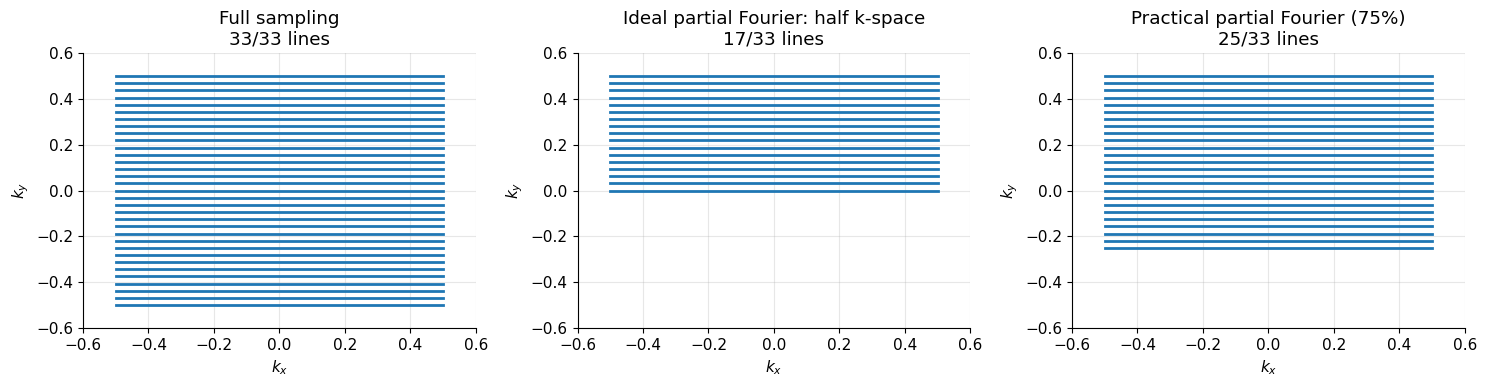

In [3]:
# k-space sampling patterns for partial Fourier imaging (each line = one acquired k_y line)
N = 32
k = np.linspace(-N / 2, N / 2, N + 1) / N          # normalized k, -0.5 ... 0.5
pf_factor = 0.75

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
patterns = [("Full sampling", np.ones_like(k, bool)),
            ("Ideal partial Fourier: half k-space", k >= 0),
            (f"Practical partial Fourier ({pf_factor:.0%})", k >= -(pf_factor - 0.5))]
for ax, (title, keep) in zip(axes, patterns):
    for ky_ in k[keep]:
        ax.plot([-0.5, 0.5], [ky_, ky_], lw=2, color="C0")
    ax.set_xlim(-.6, .6); ax.set_ylim(-.6, .6); ax.set_xlabel("$k_x$"); ax.set_ylabel("$k_y$")
    ax.set_title(f"{title}\n{keep.sum()}/{len(k)} lines")
plt.tight_layout(); plt.show()

The practical pattern acquires all of the upper half plus a band of $\pm 0.25$ around the centre (the extra lines below $k_y=0$), from which the phase is estimated.

### 3.1 Reconstruction: zero-filling, naive conjugate fill, homodyne, POCS

Let $M_{PF}$ be the acquired partial k-space (zeros where not acquired), with $k_y$ lines from $-k_0$ to $+k_{max}$ ($k_0$ = width of the symmetric centre band).

1. **Zero-filling**: just inverse-FFT $M_{PF}$. Equivalent to multiplying k-space by a step-like window: correct contrast but blurring (the image is convolved with the FT of the window, which has an imaginary part: the real and imaginary parts mix).
2. **Naive conjugate synthesis**: fill missing $M(-\vec k)$ with $M^*(\vec k)$. Exact only for a real image; with a varying phase it gives errors.
3. **Homodyne detection** (Noll et al. 1991):
   * estimate a low-resolution phase $\hat\phi(\vec r)$ from the symmetric central band only;
   * weight the acquired k-space with $H(k_y)$: 2 for the part only acquired on one side, 1 within the symmetric band (a smooth ramp from 2 to 0 is common), 0 elsewhere. This makes the k-space sum "as if" both halves were present;
   * $\hat m = \mathcal{Re}\left\{\mathcal F^{-1}\{H\,M_{PF}\}\,e^{-i\hat\phi}\right\}$: demodulate the phase and keep the real part.
4. **POCS**: iterate between enforcing the low-resolution phase in image space and the acquired data in k-space.

<details><summary><b>📐 Why the factor 2 works (optional)</b></summary>

Write the phase-corrected image $\tilde m = m e^{-i\hat\phi}$, assumed real. Its k-space $\tilde M$ is conjugate symmetric, so $\mathcal{Re}\{\mathcal F^{-1}\{2\,\tilde M\,u(k)\}\} = \tilde m$ for a step $u(k)$ that is 1 for $k>0$, 0 for $k<0$ and 1/2 at $k=0$: the real part of the inverse FT of the half-plane data, doubled, equals the full real image (the imaginary part of $\mathcal F^{-1}\{u\}$ pairs with the anti-symmetric part, which is zero for real images). Homodyne uses the same idea, with the symmetric band treated with weight 1 (both halves present there), and applies the phase correction after the inverse FFT, which is valid for slowly varying phase.

</details>

We test this on the real 2D spin-echo brain data shipped with the book (`se_t1_sag_data.mat`, 256 × 256 k-space). Its image phase is smooth but definitely not constant.

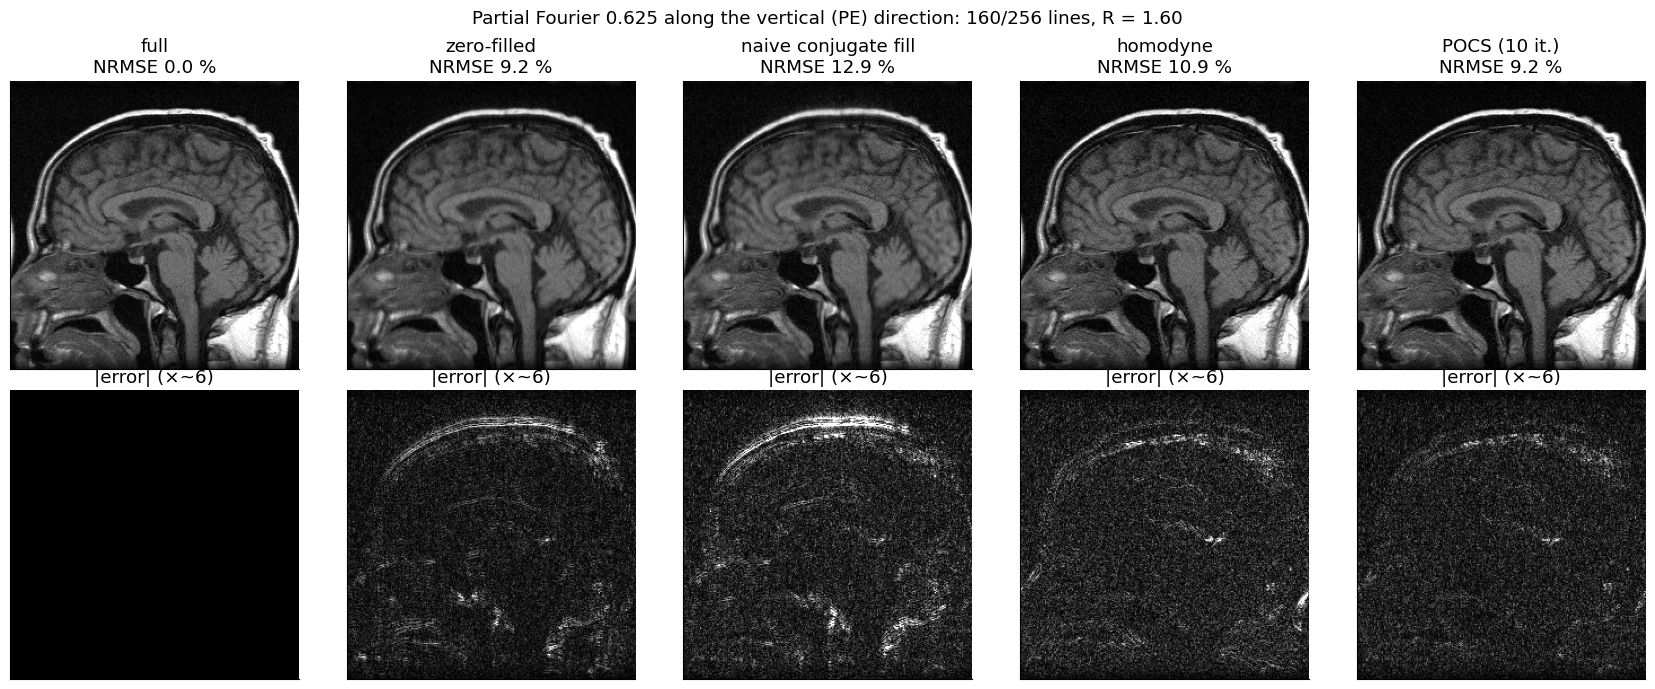

In [4]:
K_full = sio.loadmat("../data/se_t1_sag_data.mat")["data"]     # complex k-space, (ky, kx), centre at (128, 128)
img_full = mt.ifft2c(K_full)
N = K_full.shape[0]
ky = np.arange(N) - N // 2

def partial_fourier_mask(N, f_pf):
    """Acquire lines with ky index >= -(f_pf - 0.5) N (upper part + symmetric band)."""
    ky = np.arange(N) - N // 2
    return ky >= -int(round((f_pf - 0.5) * N))

def low_res_phase(K_pf, k0, N):
    """Phase from the symmetric centre band |ky| < k0, Hann-windowed (smooth)."""
    ky = np.arange(N) - N // 2
    win = np.where(np.abs(ky) < k0, 0.5 + 0.5 * np.cos(np.pi * ky / k0), 0.0)
    return np.angle(mt.ifft2c(K_pf * win[:, None]))

def homodyne(K_pf, f_pf):
    N = K_pf.shape[0]
    ky = np.arange(N) - N // 2
    k0 = int(round((f_pf - 0.5) * N))                # half-width of the symmetric band
    H = np.zeros(N)
    H[ky >= -k0] = 1.0
    H[ky > k0] = 2.0
    band = np.abs(ky) <= k0                          # smooth ramp 0 -> 2 across the band
    H[band] = 1 + ky[band] / k0
    phi = low_res_phase(K_pf, k0, N)
    return np.real(mt.ifft2c(K_pf * H[:, None]) * np.exp(-1j * phi))

def pocs(K_pf, f_pf, n_iter=10):
    N = K_pf.shape[0]
    mask = partial_fourier_mask(N, f_pf)
    k0 = int(round((f_pf - 0.5) * N))
    phi = low_res_phase(K_pf, k0, N)
    K = K_pf.copy()
    for _ in range(n_iter):
        x = mt.ifft2c(K)
        x = np.abs(x) * np.exp(1j * phi)             # project onto "images with phase phi"
        K = mt.fft2c(x)
        K[mask] = K_pf[mask]                          # project onto "consistent with acquired data"
    return mt.ifft2c(K)

def conj_fill(K_pf, f_pf):
    """Naive conjugate synthesis (assumes a real image, ignores phase)."""
    N = K_pf.shape[0]
    mask = partial_fourier_mask(N, f_pf)
    neg = (N - np.arange(N)) % N
    Kc = K_pf.copy()
    Kflip = np.conj(K_pf[neg][:, neg])               # M*(-k)
    Kc[~mask] = Kflip[~mask]
    return mt.ifft2c(Kc)

f_pf = 5 / 8
mask = partial_fourier_mask(N, f_pf)
K_pf = K_full * mask[:, None]
recs = {"full": np.abs(img_full),
        "zero-filled": np.abs(mt.ifft2c(K_pf)),
        "naive conjugate fill": np.abs(conj_fill(K_pf, f_pf)),
        "homodyne": np.abs(homodyne(K_pf, f_pf)),
        "POCS (10 it.)": np.abs(pocs(K_pf, f_pf))}
ref = recs["full"]
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for j, (name, im) in enumerate(recs.items()):
    err = np.linalg.norm(im - ref) / np.linalg.norm(ref)
    mt.show_image(im, ax=axes[0, j], title=f"{name}\nNRMSE {err*100:.1f} %", vmax=ref.max() * 0.8)
    mt.show_image(np.abs(im - ref), ax=axes[1, j], vmax=ref.max() * 0.15, title="|error| (×~6)")
plt.suptitle(f"Partial Fourier {f_pf:.3f} along the vertical (PE) direction: {mask.sum()}/{N} lines, R = {N/mask.sum():.2f}")
plt.tight_layout(); plt.show()

* **Zero-filling** keeps the contrast but blurs along the PE direction.
* **Naive conjugate fill** produces large errors because the brain image phase is not constant.
* **Homodyne** and **POCS** are both good, with errors mainly at sharp edges where the phase or the magnitude changes quickly. They do discard the true phase (homodyne returns a real image).

The smooth-phase assumption is the key. Let's break it with a localized, rapidly varying phase (as from flow in a vessel, or near an air–tissue interface):

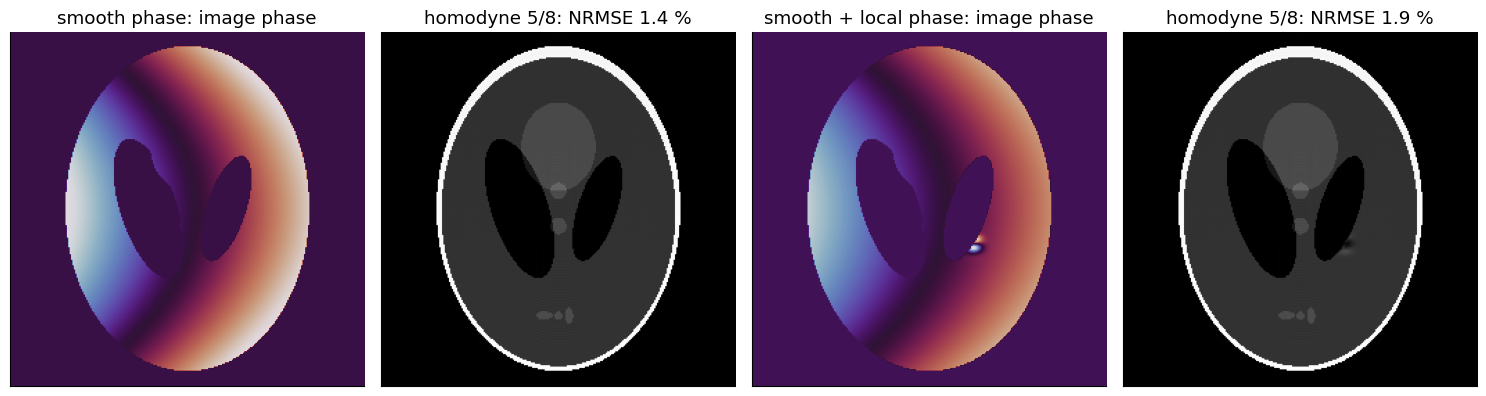

In [5]:
# Synthetic test: smooth phase vs. smooth + localized rapidly varying phase
Np = 256
yy, xx = np.mgrid[1:-1:Np * 1j, -1:1:Np * 1j]
mag = mt.shepp_logan(Np)
phase_smooth = 1.5 * xx + 1.0 * yy ** 2                          # [rad] coil / B0-like
phase_local = 2.5 * np.exp(-((xx - 0.25) ** 2 + (yy + 0.2) ** 2) / (2 * 0.03 ** 2)) * np.cos(40 * yy)
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for j, (name, ph) in enumerate([("smooth phase", phase_smooth), ("smooth + local phase", phase_smooth + phase_local)]):
    Kp = mt.fft2c(mag * np.exp(1j * ph)) * partial_fourier_mask(Np, f_pf)[:, None]
    hd = np.abs(homodyne(Kp, f_pf))
    err = np.linalg.norm(hd - mag) / np.linalg.norm(mag)
    axes[2 * j].imshow(np.angle(np.exp(1j * ph)) * (mag > 0), cmap="twilight"); axes[2 * j].set_title(f"{name}: image phase")
    axes[2 * j].set_xticks([]); axes[2 * j].set_yticks([])
    mt.show_image(hd, ax=axes[2 * j + 1], title=f"homodyne 5/8: NRMSE {err*100:.1f} %")
plt.tight_layout(); plt.show()

With only smooth phase, homodyne is nearly perfect. With a localized high-frequency phase pattern, its low-resolution phase estimate is wrong there, and the real-part operation loses or distorts signal in that region. So: **don't use partial Fourier when phase matters** (phase-contrast flow imaging, susceptibility-weighted imaging, some fat–water methods), and be careful near strong susceptibility gradients.

> **🔧 Engineering reality:** Partial Fourier is used in two directions. In the **PE direction** it saves scan time (e.g. 5/8 in single-shot FSE "HASTE": about half the echoes). In the **readout direction** ("partial echo", "asymmetric echo") it lets the echo occur early in the readout window, shortening TE (e.g. in fast GRE and diffusion EPI). SNR drops by about $\sqrt{f_{PF}}$ (fewer samples), slightly more with homodyne weighting.

## 4. Parallel imaging

**Parallel imaging (PI)** uses the spatial information provided by the individual elements of a receive **coil array** to accelerate image acquisition. Each element is most sensitive to tissue close to it (receive sensitivity $C_n(\vec r)$, see [RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb)). With multiple elements, the coils provide additional coarse localization information. The primary parallel imaging approach is to undersample k-space by **skipping phase-encoding lines**. Another approach is to excite and acquire multiple slices simultaneously: **simultaneous multi-slice (SMS)** imaging.

The signal of coil $n$ is the signal equation weighted by its sensitivity:

$$s_n(t) = \int C_n(\vec r)\, m(\vec r)\, e^{-i2\pi\vec k(t)\cdot\vec r}\, d\vec r .$$

In words: each coil sees the same object, but multiplied by its own spatial "spotlight" $C_n$; so coil $n$'s k-space is the Fourier transform of $C_n m$,

where $s_n(t)$ is the signal of coil $n$, $C_n(\vec r)$ its complex sensitivity, $m(\vec r)$ the image and $\vec k(t)$ the k-space trajectory.

### 4.1 Synthetic coil sensitivities from Biot–Savart

By reciprocity (see [Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb)), the receive sensitivity of a loop coil is proportional to the transverse magnetic field it would produce at $\vec r$ if driven with unit current. We compute this with `mt.loop_coil_field` (Biot–Savart, [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb)) for 8 circular loops (radius 5 cm) arranged around the head, and use $C_n \propto B_x - iB_y$, the circularly polarized component that couples to clockwise-precessing magnetization (the conjugation convention differs between textbooks; it only flips the sign of the phase).

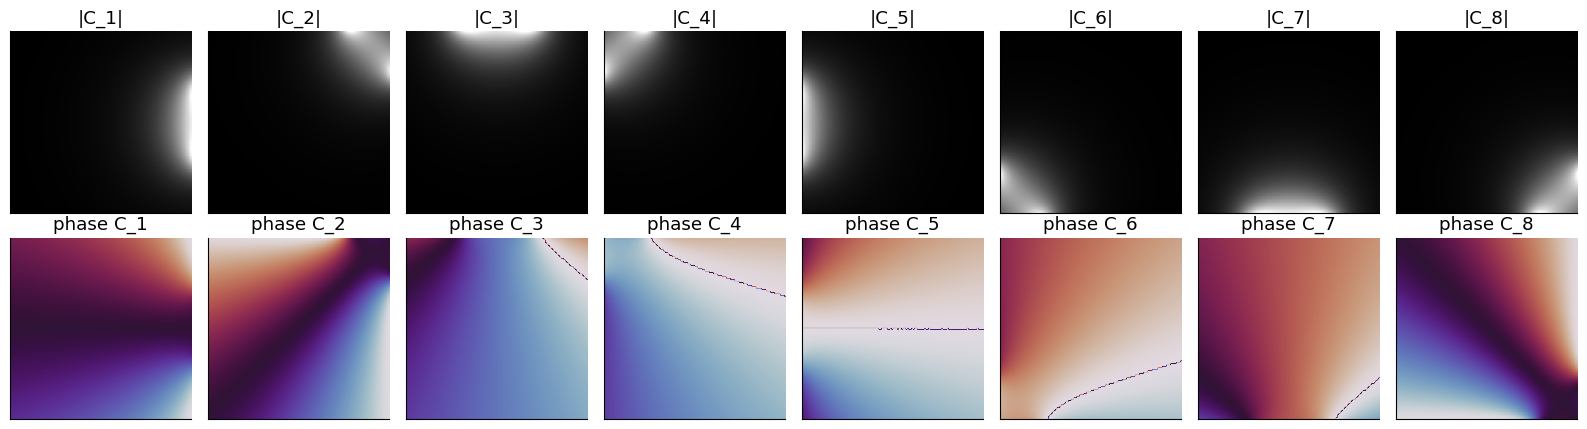

In [6]:
def coil_sensitivities(N, FOV, n_coils=8, R_array=0.14, loop_radius=0.05, z_slice=0.0, z_coils=(0.0,),
                       n_segments=64):
    """Complex receive sensitivities C_n of loop coils around the object (Biot-Savart).

    N x N grid covering FOV [m] in the plane z = z_slice; loops of radius loop_radius [m] at distance
    R_array [m] from the centre, axis pointing radially, one ring per entry of z_coils [m].
    Returns array (N_c, N, N), normalized so that max of the root-sum-of-squares is 1.
    Image convention: row index = y (top = +y), column index = x."""
    x = (np.arange(N) - N // 2) * FOV / N
    X, Y = np.meshgrid(x, -x)
    pts = np.stack([X, Y, np.full_like(X, z_slice)], axis=-1)
    C = []
    for zc in z_coils:
        for j in range(n_coils):
            a = 2 * np.pi * j / n_coils
            p_rot = pts @ mt.Rz(-a).T                            # rotate the points by -a ...
            B = mt.loop_coil_field(p_rot, loop_radius, center=(R_array, 0, zc), normal="x", n_segments=n_segments)
            B = B @ mt.Rz(a).T                                   # ... and the field back by +a
            C.append(B[..., 0] - 1j * B[..., 1])                 # transverse, circularly polarized part
    C = np.array(C)
    return C / np.sqrt(np.sum(np.abs(C) ** 2, axis=0)).max()

N, FOV = 128, 0.24
C = coil_sensitivities(N, FOV)
m_true = mt.shepp_logan(N)
obj = m_true > 0

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for j in range(8):
    mt.show_image(np.abs(C[j]), ax=axes[0, j], title=f"|C_{j+1}|")
    axes[1, j].imshow(np.angle(C[j]), cmap="twilight"); axes[1, j].set_xticks([]); axes[1, j].set_yticks([])
    axes[1, j].set_title(f"phase C_{j+1}")
plt.tight_layout(); plt.show()

Each coil "sees" mainly the region close to it, and the sensitivities have smoothly varying phase. In a real scanner, sensitivities are measured or estimated; we use these simulated ones as the ground truth.

### 4.2 Undersampling → aliasing

Skipping every other PE line doubles $\Delta k_y$, which halves the FOV (since $FOV=1/\Delta k_y$). Everything outside the reduced FOV folds back: the image becomes the sum of copies shifted by $FOV/R$ (sampling ↔ replication, see [Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)). For coil $n$:

$$a_n(y) = \sum_{\rho=0}^{R-1} C_n\!\left(y + \rho\tfrac{FOV}{R}\right) m\!\left(y+\rho\tfrac{FOV}{R}\right), \qquad 0\le y<\tfrac{FOV}{R}.$$

In words: the aliased image value of coil $n$ at position $y$ is the sum of the $R$ true pixel values that fold onto $y$, each weighted by that coil's sensitivity at the original location,

where $a_n(y)$ is coil $n$'s aliased image (reconstructed by plain inverse FFT of the undersampled data, scaled by $R$), $R$ the acceleration factor and $\rho$ indexes the folded copies.

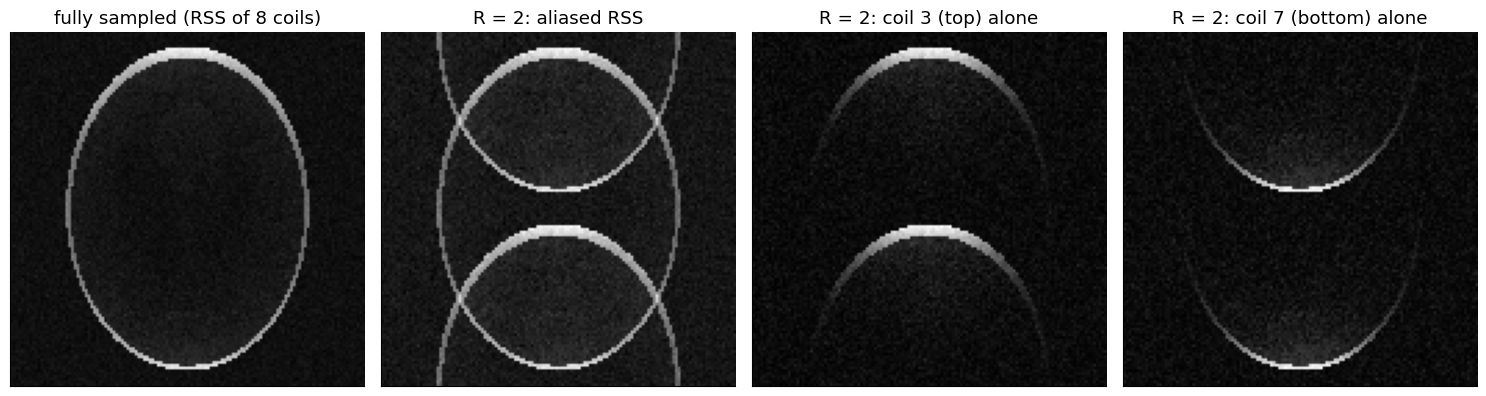

In [7]:
sigma = 0.01                                          # noise std per k-space sample (real and imag.)
K_coils = mt.fft2c(C * m_true)                        # fully sampled k-space of each coil (N_c, ky, kx)
K_noisy = mt.add_complex_noise(K_coils, sigma, rng=np.random.default_rng(1))

def undersample(K, R):
    """Keep every R-th k_y line (rows), zero elsewhere."""
    Ku = np.zeros_like(K)
    Ku[..., ::R, :] = K[..., ::R, :]
    return Ku

R = 2
alias = mt.ifft2c(undersample(K_noisy, R)) * R        # scaling R keeps the folded signal at full amplitude
rss = lambda imgs: np.sqrt(np.sum(np.abs(imgs) ** 2, axis=0))   # root-sum-of-squares coil combination
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
mt.show_image(rss(mt.ifft2c(K_noisy)), ax=axes[0], title="fully sampled (RSS of 8 coils)")
mt.show_image(rss(alias), ax=axes[1], title=f"R = {R}: aliased RSS")
mt.show_image(alias[2], ax=axes[2], title="R = 2: coil 3 (top) alone")
mt.show_image(alias[6], ax=axes[3], title="R = 2: coil 7 (bottom) alone")
plt.tight_layout(); plt.show()

The aliased images of individual coils differ: the top coil mostly sees the top half of the head and its folded copy is weak, and vice versa. That difference is what SENSE exploits.

### 4.3 SENSE: a small linear system per aliased pixel set

**SENSE** (SENSitivity Encoding, Pruessmann et al. 1999) solves the folding equation directly. For one aliased location, collect the $N_c$ coil values in a vector $\vec a$ and the $R$ unknown true pixel values in $\vec v$:

$$\vec a = \mathbf C\,\vec v + \vec n,\qquad \vec a = \begin{bmatrix}a_1\\ \vdots\\ a_{N_c}\end{bmatrix},\ \ \mathbf C = \begin{bmatrix}C_1(y_0) & \cdots & C_1(y_{R-1})\\ \vdots & & \vdots\\ C_{N_c}(y_0) & \cdots & C_{N_c}(y_{R-1})\end{bmatrix},\ \ \vec v = \begin{bmatrix}m(y_0)\\ \vdots\\ m(y_{R-1})\end{bmatrix}.$$

In words: each coil gives one equation, "my aliased value = the sum of the folded pixels weighted by my sensitivities". With $N_c\ge R$ coils we have at least as many equations as unknowns,

where $y_\rho = y + \rho\,FOV/R$ are the folding positions, $\mathbf C$ is $N_c\times R$, and $\vec n$ the noise in the aliased coil images, with $N_c\times N_c$ **noise covariance** $\Psi = \mathrm{E}[\vec n\vec n^H]$ (coils share noise sources, so $\Psi$ is not diagonal).

The best linear unbiased estimate (weighted least squares, derivation in [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb)) is

$$\hat{\vec v} = \mathbf U\,\vec a,\qquad \mathbf U = \left(\mathbf C^H\Psi^{-1}\mathbf C\right)^{-1}\mathbf C^H\Psi^{-1} .$$

In words: we "unfold" by solving the over-determined system in the least-squares sense, giving less weight to noisy and correlated coils ($\Psi^{-1}$),

where $^H$ is the conjugate transpose and $\mathbf U$ the $R\times N_c$ unfolding matrix. This is solved for **every** aliased pixel set: $N^2/R$ tiny systems.

### 4.4 The g-factor

The noise covariance of the unfolded pixels is $\mathbf U\Psi\mathbf U^H = (\mathbf C^H\Psi^{-1}\mathbf C)^{-1}$. Comparing the noise of pixel $\rho$ with that of an optimal full-FOV coil combination gives the **geometry factor**

$$g_\rho = \sqrt{\left[\left(\mathbf C^H\Psi^{-1}\mathbf C\right)^{-1}\right]_{\rho\rho}\;\left[\mathbf C^H\Psi^{-1}\mathbf C\right]_{\rho\rho}}\ \ \ge 1 .$$

In words: the first factor is the noise variance of the unfolded pixel, the second is the inverse noise variance the same pixel would have without folding (no other pixel to separate it from). Their product is 1 if the sensitivity columns of the folded pixels are orthogonal, and grows when they look alike, i.e. when the system is ill-conditioned,

where $[\cdot]_{\rho\rho}$ is the $\rho$-th diagonal element. The resulting SNR is

$$SNR_{acc}(\vec r) = \frac{SNR_{full}(\vec r)}{g(\vec r)\,\sqrt R}.$$

In words: we lose $\sqrt R$ because we sample $R$ times less (less measurement time, [Signal to Noise Ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb)) and a further factor $g$ because unfolding amplifies noise. The $\sqrt R$ loss is unavoidable; $g$ depends on the coil geometry, the direction and pattern of undersampling, and the position.

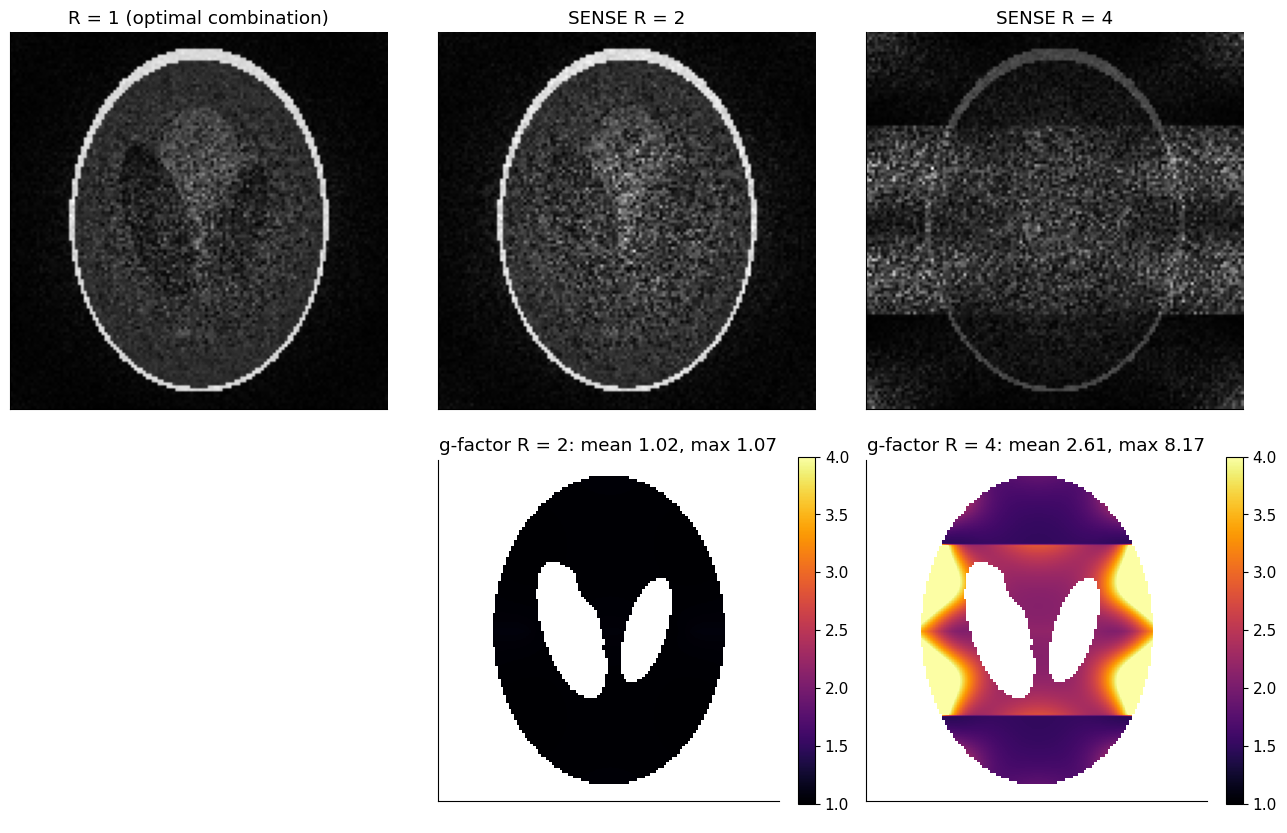

In [8]:
def sense_unfold(alias, C, R, Psi=None, reg=1e-9):
    """SENSE unfolding for regular undersampling by R along rows (axis -2).

    alias: (N_c, N, N) aliased coil images (scaled by R, periodic with period N/R in rows)
    C: (N_c, N, N) sensitivities; Psi: (N_c, N_c) noise covariance (identity if None).
    Returns (image, g-factor map)."""
    Nc, N, _ = C.shape
    Psi = np.eye(Nc) if Psi is None else Psi
    Pinv = np.linalg.inv(Psi)
    img = np.zeros((N, N), complex)
    g = np.zeros((N, N))
    Ny = N // R
    for y in range(Ny):
        rows = [y + r * Ny for r in range(R)]                # the R rows that fold onto row y
        Cm = C[:, rows, :].transpose(2, 0, 1)                # (N_x, N_c, R): one small C per column x
        a = alias[:, y, :].T[..., None]                      # (N_x, N_c, 1)
        CH = np.conj(Cm).transpose(0, 2, 1)                  # (N_x, R, N_c)
        A = CH @ Pinv @ Cm + reg * np.eye(R)                 # C^H Psi^-1 C   (N_x, R, R)
        v = np.linalg.solve(A, CH @ Pinv @ a)[..., 0]        # unfolded pixel values (N_x, R)
        Ainv = np.linalg.inv(A)
        for r, row in enumerate(rows):
            img[row] = v[:, r]
            g[row] = np.sqrt(np.abs(Ainv[:, r, r] * A[:, r, r]))
    return img, g

# a realistic noise covariance: equal variance, correlation 0.2 between neighbouring coils
Nc = C.shape[0]
Psi = np.eye(Nc)
for j in range(Nc):
    Psi[j, (j + 1) % Nc] = Psi[(j + 1) % Nc, j] = 0.2
L = np.linalg.cholesky(Psi)                             # correlated noise = L @ white noise

def coil_noise(shape, sigma, rng):
    w = sigma * (rng.standard_normal(shape) + 1j * rng.standard_normal(shape))
    return np.einsum("ij,j...->i...", L, w)

rng = np.random.default_rng(2)
K_noisy = K_coils + coil_noise(K_coils.shape, sigma, rng)

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
img_R1, _ = sense_unfold(mt.ifft2c(K_noisy), C, 1, Psi)      # R = 1: optimal (Roemer) coil combination
mt.show_image(img_R1, ax=axes[0, 0], title="R = 1 (optimal combination)")
axes[1, 0].axis("off")
for j, R in enumerate([2, 4]):
    alias = mt.ifft2c(undersample(K_noisy, R)) * R
    img_R, g = sense_unfold(alias, C, R, Psi)
    mt.show_image(img_R, ax=axes[0, j + 1], title=f"SENSE R = {R}")
    im = axes[1, j + 1].imshow(np.where(obj, g, np.nan), cmap="inferno", vmin=1, vmax=4)
    axes[1, j + 1].set_xticks([]); axes[1, j + 1].set_yticks([])
    axes[1, j + 1].set_title(f"g-factor R = {R}: mean {g[obj].mean():.2f}, max {g[obj].max():.2f}")
    plt.colorbar(im, ax=axes[1, j + 1], fraction=0.046)
plt.tight_layout(); plt.show()

At $R=2$ unfolding is nearly perfect and $g\approx1$ almost everywhere: the 8-coil ring separates top and bottom well. At $R=4$ (only 32 of 128 lines) four pixels must be separated; the $g$-factor rises, especially in the **centre**, where all coils have similar, weak sensitivity. The noise in the $R=4$ image is visibly larger and structured.

Let's verify $SNR_{acc}=SNR_{full}/(g\sqrt R)$ with a Monte-Carlo **pseudo-replica** experiment: reconstruct many noise realizations and measure the noise standard deviation pixel by pixel.

In [9]:
n_rep = 40
rng = np.random.default_rng(5)
recs = {1: [], 2: [], 4: []}
for _ in range(n_rep):
    Kn = K_coils + coil_noise(K_coils.shape, sigma, rng)
    for R in recs:
        alias = mt.ifft2c(undersample(Kn, R)) * R
        recs[R].append(sense_unfold(alias, C, R, Psi)[0])
noise_sd = {R: np.std(np.array(v), axis=0) for R, v in recs.items()}
for R in (2, 4):
    g_meas = noise_sd[R] / (noise_sd[1] * np.sqrt(R))       # = SNR_full / (SNR_acc sqrt(R))
    _, g_theo = sense_unfold(np.zeros_like(C), C, R, Psi)
    print(f"R = {R}: mean g (Monte Carlo) = {g_meas[obj].mean():.3f},  mean g (formula) = {g_theo[obj].mean():.3f};"
          f"  SNR_acc/SNR_full = {np.mean(noise_sd[1][obj]/noise_sd[R][obj]):.3f}"
          f"  vs 1/(g sqrt R) = {np.mean(1/(g_theo[obj]*np.sqrt(R))):.3f}")

R = 2: mean g (Monte Carlo) = 1.022,  mean g (formula) = 1.018;  SNR_acc/SNR_full = 0.697  vs 1/(g sqrt R) = 0.695
R = 4: mean g (Monte Carlo) = 2.623,  mean g (formula) = 2.608;  SNR_acc/SNR_full = 0.228  vs 1/(g sqrt R) = 0.226


The measured noise amplification matches the formula: the SNR penalty is $g\sqrt R$.

> **🧭 Intuition:** The g-factor measures how "different" the coils' views of the folded pixels are. If two pixels that fold onto each other are seen by the coils with nearly the same weights (columns of $\mathbf C$ nearly parallel), separating them amplifies noise, just like solving a nearly singular linear system. Coils should vary strongly **along the undersampled direction**; that is why coil arrays have many small elements distributed around the body, and why scanners let you choose the PE direction.

### 4.5 Coil sensitivities in practice, and what goes wrong

Coil sensitivities can be measured with a coarse (fast) **pre-scan**, using the relatively uniform **body coil** as a reference: $C_n \approx m_n/m_{body}$. Or they can be estimated from fully sampled low-resolution data of the scan itself: $C_n \approx m_n^{low}/\sqrt{\sum_c |m_c^{low}|^2}$. The popular **SENSE** method (Philips "SENSE", Siemens "mSENSE", GE "ASSET") uses such maps. It suffers from **residual aliasing** if the measured sensitivities don't match those during the accelerated scan, e.g. due to motion between the pre-scan and the scan.

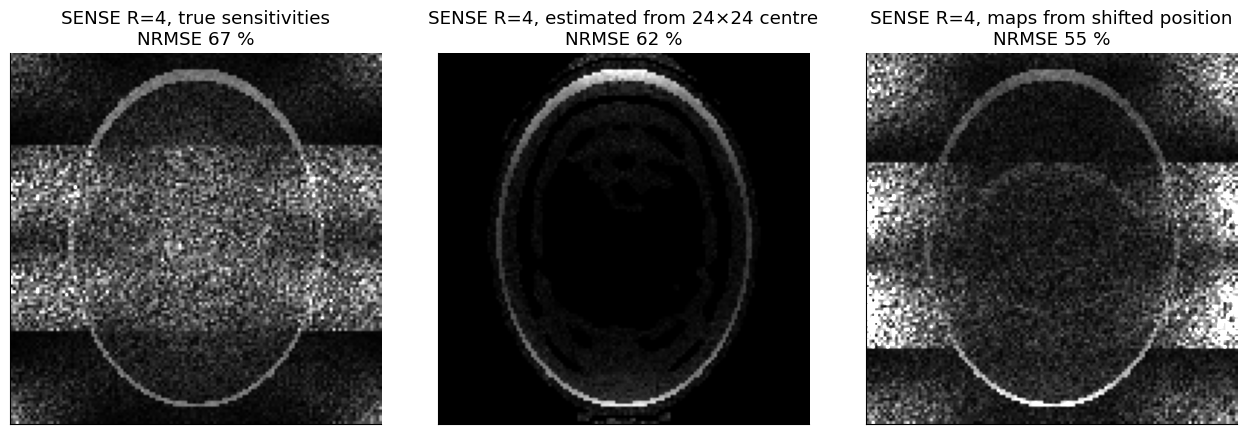

In [10]:
# (a) sensitivities estimated from the central 24 k-space lines of the data itself
n_cal = 24
Kcal = np.zeros_like(K_noisy)
c0 = N // 2
Kcal[:, c0 - n_cal // 2:c0 + n_cal // 2, c0 - n_cal // 2:c0 + n_cal // 2] = K_noisy[:, c0 - n_cal // 2:c0 + n_cal // 2, c0 - n_cal // 2:c0 + n_cal // 2]
low = mt.ifft2c(Kcal)
C_est = low / np.maximum(rss(low), 1e-6) * (rss(low) > 0.1 * rss(low).max())   # mask out background

# (b) "motion": the coil maps were measured with the head 6 pixels lower
C_moved = np.roll(C, 6, axis=1)

R = 4
alias = mt.ifft2c(undersample(K_noisy, R)) * R
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, (name, Cuse) in zip(axes, [("true sensitivities", C), ("estimated from 24×24 centre", C_est), ("maps from shifted position", C_moved)]):
    rec, _ = sense_unfold(alias, Cuse, R, Psi)
    rec_mag = np.abs(rec) * (rss(C) if name != "true sensitivities" else 1)   # estimated maps carry an RSS normalization
    rec_mag = rec_mag / np.percentile(rec_mag[obj], 99)
    err = np.linalg.norm((rec_mag - m_true / np.percentile(m_true[obj], 99))[obj]) / np.linalg.norm(m_true[obj] / np.percentile(m_true[obj], 99))
    mt.show_image(rec_mag, ax=ax, vmax=1.2, title=f"SENSE R=4, {name}\nNRMSE {err*100:.0f} %")
plt.tight_layout(); plt.show()

Self-calibrated maps work well (they absorb the RSS weighting, which is why the image intensity is renormalized here). Maps that are spatially inconsistent with the data leave **residual aliasing**: ghost copies of edges at multiples of $FOV/R$.

### 4.6 GRAPPA: parallel imaging in k-space

Methods that estimate the coil information from the data typically require a fully sampled **calibration region** (autocalibration signal, **ACS**) in the centre of k-space. This costs a little scan time but is more robust, since the calibration comes from the data being reconstructed. The most popular is **GRAPPA** (GeneRalized Autocalibrating Partially Parallel Acquisitions, Griswold et al. 2002; Siemens "GRAPPA", GE "ARC").

The idea: multiplying by a smooth $C_n$ in image space is a **convolution with a small kernel** in k-space (convolution theorem, [RM4](../refreshers/RM4_Fourier_Properties.ipynb)). So neighbouring k-space samples of all coils are linearly related, and a missing sample of coil $n$ can be predicted as a weighted sum of acquired neighbours from **all** coils:

$$M_n(k_x,k_y) \approx \sum_{c=1}^{N_c}\ \sum_{\Delta y\in\{-1,+1\}}\ \sum_{\Delta x\in\{-1,0,1\}} w_{n,c,\Delta y,\Delta x}\; M_c(k_x+\Delta x\,\Delta k_x,\ k_y+\Delta y\,\Delta k_y).$$

In words: a missing line is interpolated from the acquired lines just above and below it (here 2 lines × 3 columns × all coils), with weights that are the same everywhere in k-space,

where $M_c$ is coil $c$'s k-space and $w$ the **GRAPPA kernel** weights ($N_c\times N_c\times 2\times 3$ complex numbers). The weights are found by **least squares on the ACS region**, where both the "missing" and the "acquired" neighbours are known. This is a standard linear regression, $\mathbf A\mathbf w=\mathbf b$, solved with a little Tikhonov regularization.

effective acceleration: 1.68  (R = 2 nominal, reduced by the ACS lines)


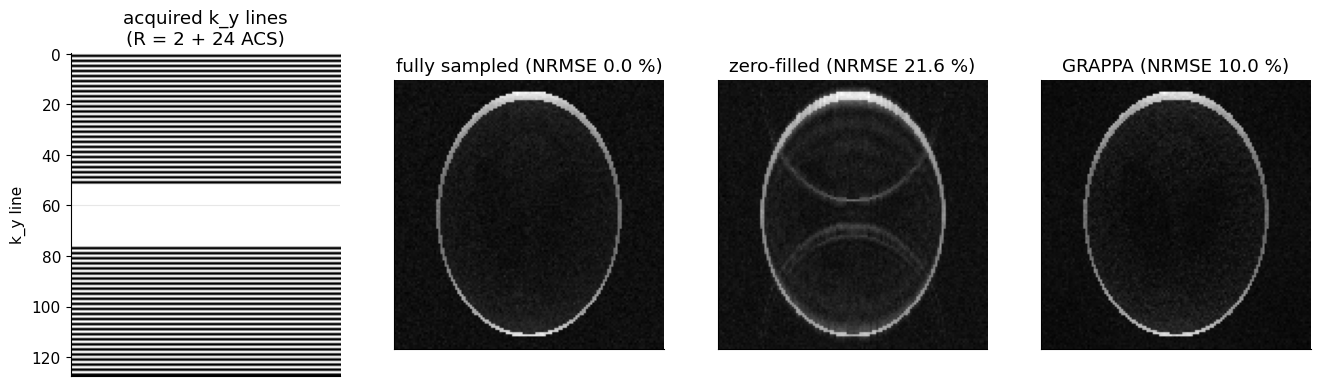

In [11]:
def grappa_r2(K, n_acs=24, lam=1e-4):
    """Minimal GRAPPA for R = 2 along k_y with a 2 (ky) x 3 (kx) kernel. K: (N_c, Ny, Nx) full data.

    Returns (K_acquired, K_reconstructed, sampling mask). Missing lines y are predicted from y-1 and y+1."""
    Nc, Ny, Nx = K.shape
    samp = np.zeros(Ny, bool); samp[::2] = True
    acs = np.zeros(Ny, bool); acs[Ny // 2 - n_acs // 2:Ny // 2 + n_acs // 2] = True
    Ku = K * (samp | acs)[None, :, None]                         # what the scanner acquires

    def patches(Kd, y):                                          # source points for all kx of row y
        src = np.stack([Kd[:, y - 1], Kd[:, y + 1]], axis=1)    # (Nc, 2, Nx)
        pad = np.pad(src, ((0, 0), (0, 0), (1, 1)))
        P = np.stack([pad[:, :, i:i + Nx] for i in range(3)], axis=-1)   # (Nc, 2, Nx, 3)
        return P.transpose(2, 0, 1, 3).reshape(Nx, -1)          # (Nx, Nc*2*3)

    # calibration: every ACS row with both neighbours inside the ACS is a training example
    rows = [y for y in range(1, Ny - 1) if acs[y - 1] and acs[y] and acs[y + 1]]
    A = np.concatenate([patches(Ku, y)[1:-1] for y in rows])     # (n_train, Nc*6)
    B = np.concatenate([Ku[:, y, 1:-1].T for y in rows])         # (n_train, Nc)
    AhA = A.conj().T @ A
    W = np.linalg.solve(AhA + lam * np.trace(AhA).real / AhA.shape[0] * np.eye(AhA.shape[0]), A.conj().T @ B)

    Kr = Ku.copy()
    for y in range(1, Ny - 1):
        if not (samp[y] or acs[y]):
            Kr[:, y] = (patches(Kr, y) @ W).T                    # apply the kernel to fill line y
    return Ku, Kr, samp | acs

Ku, Kr, smask = grappa_r2(K_noisy)
ref_img = rss(mt.ifft2c(K_noisy))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
axes[0].imshow(np.repeat(smask[:, None], 40, axis=1), cmap="gray", aspect="auto"); axes[0].set_title("acquired k_y lines\n(R = 2 + 24 ACS)")
axes[0].set_xticks([]); axes[0].set_ylabel("k_y line")
for ax, (name, img) in zip(axes[1:], [("fully sampled", ref_img), ("zero-filled", rss(mt.ifft2c(Ku))),
                                       ("GRAPPA", rss(mt.ifft2c(Kr)))]):
    err = np.linalg.norm((img - ref_img)[obj]) / np.linalg.norm(ref_img[obj])
    mt.show_image(img, ax=ax, title=f"{name} (NRMSE {err*100:.1f} %)")
print(f"effective acceleration: {N / smask.sum():.2f}  (R = 2 nominal, reduced by the ACS lines)")

GRAPPA removes the aliasing without ever computing a sensitivity map: the kernel "knows" the coil geometry implicitly. Note the effective acceleration is lower than 2 because of the ACS lines.

> **⚠️ Common confusion:** SENSE works in **image space** with explicit sensitivity maps; GRAPPA works in **k-space** with an interpolation kernel. Mathematically both exploit the same information, and their results are similar. Practical differences: GRAPPA tolerates inaccurate maps and tight FOVs (where SENSE maps fail if the object is larger than the FOV), SENSE gives an analytical $g$-factor and is easily combined with other priors ([J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb)).

Sampling patterns (port of the original cell, regular R = 2; regular with ACS; pseudo-random):

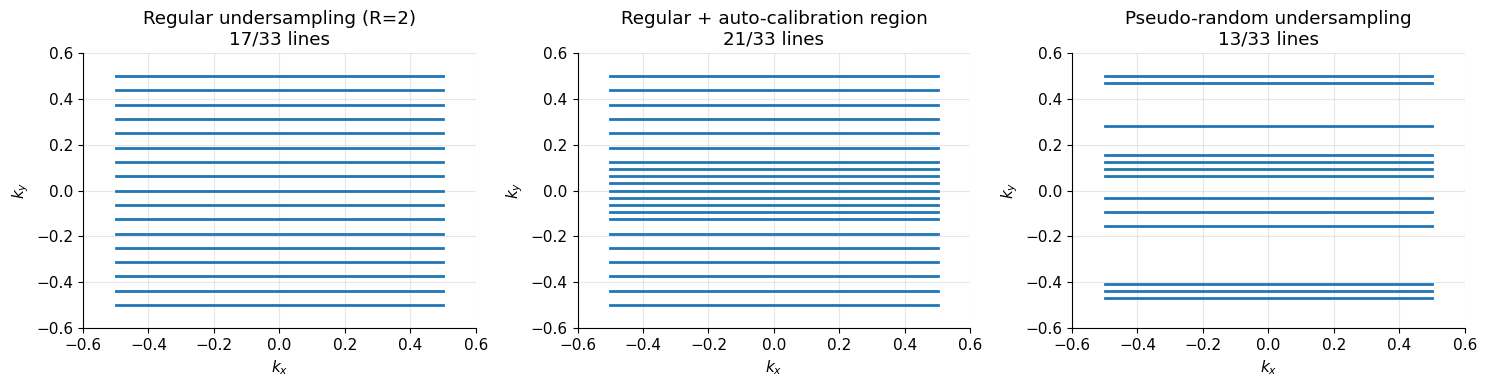

In [12]:
# k-space sampling patterns for parallel imaging and compressed sensing
N_s = 32
kk = np.linspace(-N_s / 2, N_s / 2, N_s + 1) / N_s
R_s, acs_size = 2, 8
rng_s = np.random.default_rng(0)
patterns = [("Regular undersampling (R=2)", (np.arange(N_s + 1) % R_s) == 0),
            ("Regular + auto-calibration region", ((np.arange(N_s + 1) % R_s) == 0) | (np.abs(kk) < acs_size / N_s / 2)),
            ("Pseudo-random undersampling", rng_s.random(N_s + 1) < 1 / R_s)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, keep) in zip(axes, patterns):
    for ky_ in kk[keep]:
        ax.plot([-0.5, 0.5], [ky_, ky_], lw=2, color="C0")
    ax.set_xlim(-.6, .6); ax.set_ylim(-.6, .6); ax.set_xlabel("$k_x$"); ax.set_ylabel("$k_y$")
    ax.set_title(f"{title}\n{keep.sum()}/{N_s+1} lines")
plt.tight_layout(); plt.show()

*(Ported from the original with one change: the original plotted lines along $k_x$ for some panels and along $k_y$ for others; here every pattern is drawn as acquired $k_y$ lines, i.e. full readouts along $k_x$.)*

### 4.7 Simultaneous multi-slice (SMS)

**Simultaneous multi-slice (SMS)** methods, also known as **multiband** imaging, excite and acquire multiple slices simultaneously, then use the coil sensitivities in the reconstruction to separate the signals from each slice. The RF excitation pulse must excite multiple slice locations. Naively this is done by summing frequency-shifted RF pulses, one per slice: $b_1^{MB}(t)=\sum_s b_1(t)e^{i2\pi f_{off,s}t}$ ([Slice Selection](../pass2_deep_dive/E2_Slice_Selection.ipynb)). In practice, more complex designs reduce the peak power (which grows like $MB^2$ in the worst case) and improve robustness ([RF Pulse Design](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb)). The k-space data contain the **superposition** of the signals from all excited slices.

![Simultaneous multi-slice illustration: several slices are excited at once and collapse into one image; coil sensitivities that differ between the slices allow separating them.](../images/parallel_imaging-simultaneous_multislice.png)

SMS also often uses specialized RF phase modulation, such as **CAIPIRINHA** (Controlled Aliasing In Parallel Imaging Results IN Higher Acceleration), to improve the conditioning of the reconstruction: by adding a phase of $e^{i\pi p}$ to slice 2 on line $p$ (alternating 0/180° from line to line), slice 2 is **shifted by FOV/2** in the PE direction (shift theorem). Pixels that would collapse onto each other now come from different in-plane positions, which the coils distinguish much better.

Unlike in-plane PI, SMS costs **no $\sqrt R$ SNR penalty**: every slice is still sampled for the full time; only $g$ applies.

Let's simulate MB = 2 with two coil rings (16 elements, at $z=\pm4$ cm) and slices at $z=-2$ and $+2$ cm:

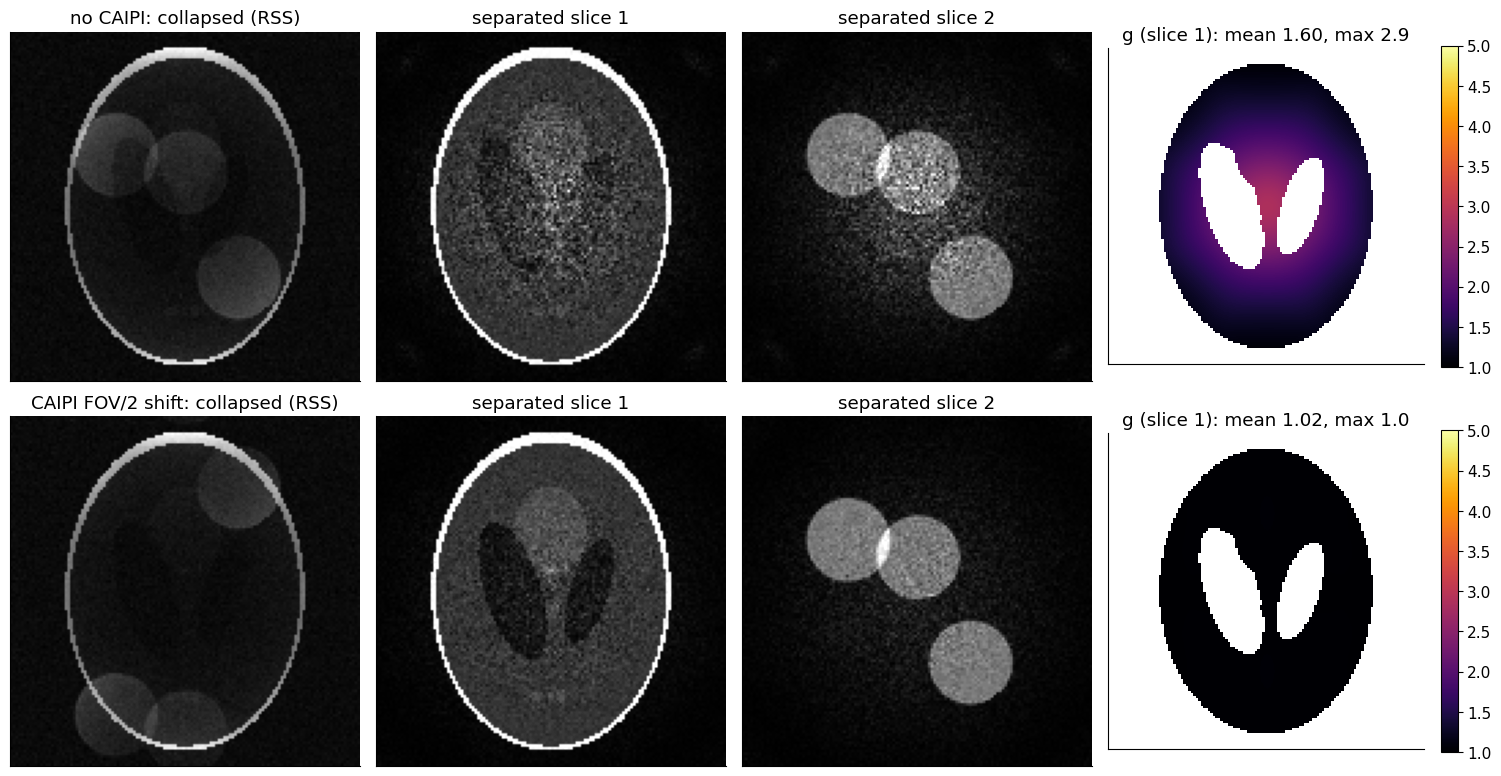

In [13]:
z1, z2 = -0.02, 0.02
C1 = coil_sensitivities(N, FOV, z_slice=z1, z_coils=(-0.04, 0.04))     # (16, N, N) sensitivities in slice 1
C2 = coil_sensitivities(N, FOV, z_slice=z2, z_coils=(-0.04, 0.04))
m1 = mt.shepp_logan(N)
m2 = np.abs(mt.ifft2c(mt.disk_phantom_kspace(N, centers=((-0.2, -0.15), (0.15, 0.2), (0.0, -0.1)), radius=0.12)))
m2 = m2 / m2.max() * (np.hypot(*np.mgrid[-1:1:N*1j, -1:1:N*1j]) < 0.75)

def sms_unfold(collapsed, Ca, Cb, shift):
    """Separate 2 slices: collapsed = Ca*m1 + roll(Cb*m2, shift). Pixel-wise 2-unknown least squares."""
    Cb_s = np.roll(Cb, shift, axis=1)
    Cm = np.stack([Ca, Cb_s], axis=-1).transpose(1, 2, 0, 3)          # (N, N, Nc, 2)
    CH = np.conj(Cm).swapaxes(-1, -2)
    A = CH @ Cm + 1e-9 * np.eye(2)
    v = np.linalg.solve(A, CH @ collapsed.transpose(1, 2, 0)[..., None])[..., 0]
    Ainv = np.linalg.inv(A)
    g = np.sqrt(np.abs(np.diagonal(Ainv, axis1=-2, axis2=-1) * np.diagonal(A, axis1=-2, axis2=-1)))
    return v[..., 0], np.roll(v[..., 1], -shift, axis=0), g[..., 0], np.roll(g[..., 1], -shift, axis=0)

rng = np.random.default_rng(7)
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for row, (name, shift) in enumerate([("no CAIPI", 0), ("CAIPI FOV/2 shift", N // 2)]):
    collapsed = C1 * m1 + np.roll(C2 * m2, shift, axis=1)              # what the coils measure
    collapsed = collapsed + 0.005 * (rng.standard_normal(collapsed.shape) + 1j * rng.standard_normal(collapsed.shape))
    r1, r2, g1, g2 = sms_unfold(collapsed, C1, C2, shift)
    mt.show_image(rss(collapsed), ax=axes[row, 0], title=f"{name}: collapsed (RSS)")
    mt.show_image(r1, ax=axes[row, 1], vmax=1, title="separated slice 1")
    mt.show_image(r2, ax=axes[row, 2], vmax=1, title="separated slice 2")
    gmask = (m1 > 0) | (m2 > 0)
    im = axes[row, 3].imshow(np.where(m1 > 0, g1, np.nan), cmap="inferno", vmin=1, vmax=5)
    axes[row, 3].set_title(f"g (slice 1): mean {np.nanmean(np.where(m1 > 0, g1, np.nan)):.2f}, max {g1[m1 > 0].max():.1f}")
    axes[row, 3].set_xticks([]); axes[row, 3].set_yticks([]); plt.colorbar(im, ax=axes[row, 3], fraction=0.046)
plt.tight_layout(); plt.show()

Without CAIPI the two slices are only 4 cm apart along $z$ and the coils barely distinguish them: high $g$, noisy separation with leakage. With the FOV/2 CAIPI shift the problem becomes an in-plane separation, which the ring array handles easily ($g$ close to 1).

> **🔧 Engineering reality:** SMS is standard in fMRI and diffusion EPI (MB 2–8 combined with in-plane $R$ 2). The limits are RF peak power and SAR of multiband pulses, slice leakage (signal of one slice appearing in another), and the need for coils with variation along the slice direction (head coils with 32–64 elements).

### 4.8 SNR and artifacts in parallel imaging

There is an SNR penalty that varies in severity with the **conditioning** of the unfolding problem. Variation in coil sensitivity profiles **in the direction of undersampling** leads to a well-conditioned reconstruction and a low SNR penalty; little variation leads to an ill-conditioned matrix and a high penalty. Regions with little difference between coils (typically the centre of the body) also have larger penalties.

The **g-factor** $g(\vec r) \geq 1$ describes this spatially varying SNR loss, which depends on the coil geometry and loading, the k-space sampling pattern and the reconstruction method. With acceleration factor $R$ the reduced total readout time also costs $\sqrt R$ (section 4.4):

$$SNR_{PI} = \frac{SNR_{full}}{g(\vec{r})\sqrt{R}}$$

Parallel imaging artifacts typically appear as **aliasing**. The undersampled data alias when no PI reconstruction is used, and sometimes the aliasing is not completely removed (high $R$, too few coils, inconsistent calibration). Aliasing-like artifacts also occur when the data and the measured coil sensitivities don't match (motion, section 4.5), and noise enhancement appears in high-$g$ regions.

## 5. Compressed sensing

**Compressed sensing (CS)** theory says that an image that is **compressible** (sparse in some domain) can be reconstructed from a subset of data samples, far fewer than Nyquist requires, provided that (1) the undersampling artifacts are **incoherent** (noise-like) in the sparse domain, and (2) the reconstruction enforces sparsity with a **non-linear** method (Lustig, Donoho & Pauly 2007). MR images are compressible (that's why JPEG works on them), so acquisition can be accelerated further with CS.

Compressed sensing for MRI uses k-space sampling patterns with **pseudo-random undersampling**, illustrated by the following diagram of the undersampled reconstruction procedure. Random sampling produces incoherent, noise-like artifacts, which can then be removed by constraining the reconstruction to a solution that is sparse in some transform domain.

![Compressed sensing illustration (animated)](../images/compressed_sensing_concept.gif)

**Caption** (figure from https://doi.org/10.1109/MSP.2007.914728): Heuristic procedure for reconstruction from undersampled data. A sparse signal (a) is 8-fold undersampled in its 1-D k-space domain (b). Equispaced undersampling results in signal aliasing (d), preventing recovery. Pseudo-random undersampling results in incoherent interference (c). Some strong signal components stick out above the interference level, are detected and recovered by thresholding (e) and (f). The interference of these components is computed (g) and subtracted (h), thus lowering the total interference level and enabling recovery of weaker components.

We now reproduce this procedure ourselves.

### 5.1 Coherent vs incoherent aliasing (1D)

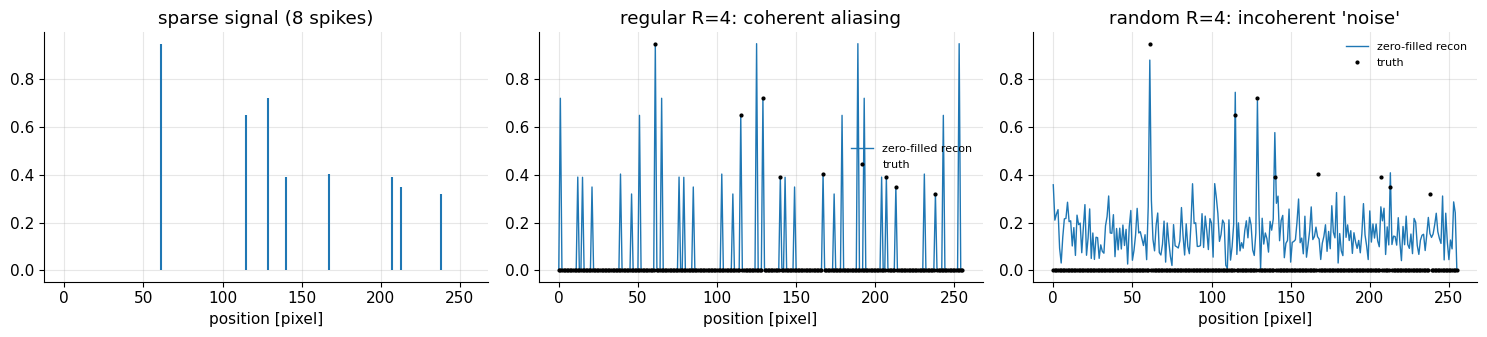

In [14]:
# A sparse 1D "image" (a few spikes), undersampled 4x regularly vs randomly
Nn = 256
rng = np.random.default_rng(11)
x_true = np.zeros(Nn, complex)
x_true[rng.choice(Nn, 8, replace=False)] = rng.uniform(0.3, 1.0, 8) * np.exp(1j * rng.uniform(0, 2 * np.pi, 8))
X = mt.fftc(x_true)
R1 = 4
mask_reg = np.zeros(Nn, bool); mask_reg[::R1] = True
mask_rnd = np.zeros(Nn, bool); mask_rnd[rng.choice(Nn, Nn // R1, replace=False)] = True

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].stem(np.abs(x_true), markerfmt=" ", basefmt=" "); axes[0].set_title("sparse signal (8 spikes)")
for ax, (name, mk) in zip(axes[1:], [("regular R=4: coherent aliasing", mask_reg), ("random R=4: incoherent 'noise'", mask_rnd)]):
    zf = mt.ifftc(X * mk) * R1                    # zero-filled reconstruction, scaled
    ax.plot(np.abs(zf), lw=1, label="zero-filled recon"); ax.plot(np.abs(x_true), "k.", ms=4, label="truth")
    ax.set_title(name); ax.legend(fontsize=8)
for ax in axes: ax.set_xlabel("position [pixel]")
plt.tight_layout(); plt.show()

Regular undersampling produces exact replicas of every spike (4 copies with equal height): no way to tell which is real. Random undersampling leaves the true spikes standing out of a noise-like background, which thresholding can exploit.

### 5.2 The optimization problem and soft-thresholding

The CS reconstruction solves

$$\hat m = \arg\min_m\ \tfrac12\lVert \mathbf E m - \vec y\rVert_2^2 + \lambda\,\lVert \mathbf W m\rVert_1 .$$

In words: find the image whose simulated measurements $\mathbf E m$ agree with the acquired data $\vec y$ (first term, **data consistency**) while having as few/small coefficients as possible in the sparse domain (second term, **sparsity**),

where $\mathbf E$ = "Fourier transform, then keep only the acquired samples" (with coils: also multiply by $C_n$), $\vec y$ the measured samples, $\mathbf W$ the sparsifying transform (identity for the spikes, a wavelet for images), $\lVert\vec u\rVert_1=\sum_i |u_i|$, and $\lambda>0$ the regularization weight.

Why $\ell_1$? The $\ell_0$ "norm" (number of non-zeros) is what we really want but is combinatorial; $\ell_2$ spreads energy over many small coefficients (it does not favour sparsity); $\ell_1$ is the closest **convex** relative of $\ell_0$ and its minimizers are typically sparse.

The workhorse algorithm is **ISTA** (iterative soft-thresholding):

$$m^{(j+1)} = \mathbf W^H\,\mathcal S_{t\lambda}\!\left(\mathbf W\left[m^{(j)} + t\,\mathbf E^H\!\left(\vec y - \mathbf E m^{(j)}\right)\right]\right),\qquad \mathcal S_\tau(u) = \frac{u}{|u|}\max(|u|-\tau,\,0).$$

In words: (1) take a gradient step that reduces the data mismatch (the bracket), (2) transform to the sparse domain, (3) shrink every coefficient towards zero by $\tau=t\lambda$, setting small ones to exactly zero, (4) transform back. Repeat,

where $t$ is the step size ($t=1$ works here because $\mathbf E^H\mathbf E$ has norm 1 for an orthonormal FFT with sampling), $\mathcal S_\tau$ is the **soft-thresholding** operator acting on each complex coefficient $u$, and $\mathbf W^H=\mathbf W^{-1}$ for an orthonormal transform. This is exactly the "detect strong components, subtract their interference, repeat" procedure of the animation.

<details><summary><b>📐 Derivation (optional): soft-thresholding solves the 1D problem</b></summary>

For a single real coefficient, minimize $f(u)=\tfrac12(u-v)^2+\tau|u|$. For $u>0$: $f'(u)=u-v+\tau=0\Rightarrow u=v-\tau$, valid if $v>\tau$. For $u<0$: $u=v+\tau$, valid if $v<-\tau$. Otherwise the minimum is at the kink $u=0$ (for $|v|\le\tau$, $f$ increases on both sides of 0). Together: $u^\star=\mathrm{sign}(v)\max(|v|-\tau,0)=\mathcal S_\tau(v)$. For complex $u$ the same holds for the magnitude, with the phase unchanged. ISTA alternates a gradient step on the smooth term with this "proximal" step on the $\ell_1$ term (proximal gradient method); with an orthonormal $\mathbf W$, the $\ell_1$ term in the image domain becomes the separable $\ell_1$ term in the coefficient domain, so it decouples into these 1D problems.

</details>

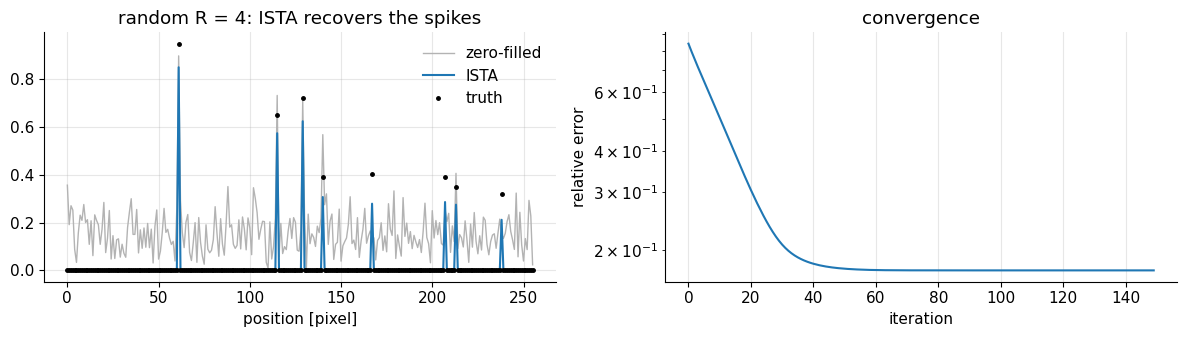

In [15]:
def soft_threshold(u, tau):
    """Complex soft-thresholding S_tau(u) = u/|u| * max(|u| - tau, 0)."""
    mag = np.abs(u)
    return np.where(mag > tau, (1 - tau / np.maximum(mag, 1e-12)) * u, 0)

def ista_1d(y, mask, lam, n_iter=100, x_true=None):
    """ISTA for a signal sparse in itself (W = identity): E = mask * fftc."""
    x = np.zeros_like(y)
    errs = []
    for _ in range(n_iter):
        x = soft_threshold(x + mt.ifftc(mask * (y - mask * mt.fftc(x))), lam)
        if x_true is not None:
            errs.append(np.linalg.norm(x - x_true) / np.linalg.norm(x_true))
    return x, errs

y1 = mt.add_complex_noise(X, 0.005, rng=np.random.default_rng(3)) * mask_rnd
x_cs, errs = ista_1d(y1, mask_rnd, lam=0.02, n_iter=150, x_true=x_true)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(np.abs(mt.ifftc(y1)) * R1, color="0.7", lw=1, label="zero-filled")
axes[0].plot(np.abs(x_cs), lw=1.5, label="ISTA")
axes[0].plot(np.abs(x_true), "k.", ms=5, label="truth"); axes[0].legend(); axes[0].set_xlabel("position [pixel]")
axes[0].set_title("random R = 4: ISTA recovers the spikes")
axes[1].semilogy(errs); axes[1].set_xlabel("iteration"); axes[1].set_ylabel("relative error"); axes[1].set_title("convergence")
plt.tight_layout(); plt.show()

ISTA recovers all spikes from a quarter of the samples. (Their heights are slightly reduced: soft-thresholding shrinks every coefficient by $\tau$, a known bias of $\ell_1$.) The error plateaus at the noise level.

### 5.3 A sparsifying transform: the Haar wavelet

Real images aren't sparse in pixel space, but they are compressible in a **wavelet** domain: most wavelet coefficients of piecewise-smooth images are tiny. The simplest wavelet is the **Haar** transform. One level replaces every pair of samples $(u_{2i},u_{2i+1})$ by their scaled sum and difference, $\left(\frac{u_{2i}+u_{2i+1}}{\sqrt2},\ \frac{u_{2i}-u_{2i+1}}{\sqrt2}\right)$. That is an orthonormal 2×2 rotation, so the whole transform is orthonormal ($\mathbf W^H\mathbf W=\mathbf I$). In 2D we apply it along rows and columns, then repeat on the low-pass (sum) quarter for several levels. Differences are ≈0 wherever the image is flat: sparse.

perfect reconstruction: True | energy preserved: True


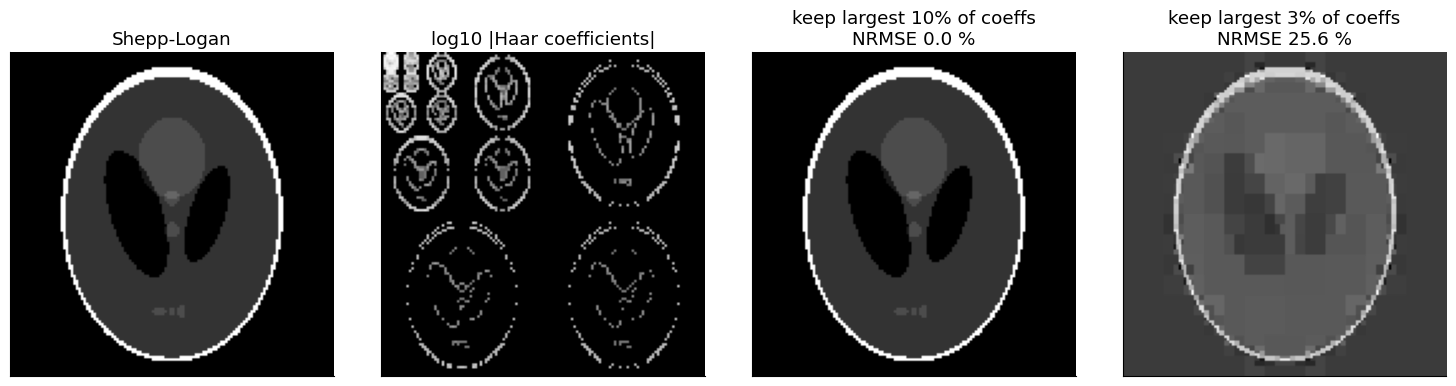

In [16]:
def haar2(x, levels=4):
    """Orthonormal 2D Haar wavelet transform (multi-level, size must be divisible by 2**levels)."""
    c = np.array(x, dtype=complex, copy=True)
    n = c.shape[0]
    for _ in range(levels):
        s = c[:n, :n]
        s = np.concatenate([(s[0::2] + s[1::2]), (s[0::2] - s[1::2])], axis=0) / np.sqrt(2)      # columns
        s = np.concatenate([(s[:, 0::2] + s[:, 1::2]), (s[:, 0::2] - s[:, 1::2])], axis=1) / np.sqrt(2)  # rows
        c[:n, :n] = s
        n //= 2
    return c

def ihaar2(c, levels=4):
    """Inverse of haar2."""
    x = np.array(c, copy=True)
    n = c.shape[0] >> (levels - 1)
    for _ in range(levels):
        s = x[:n, :n]; h = n // 2
        t = np.empty_like(s); t[:, 0::2] = (s[:, :h] + s[:, h:]) / np.sqrt(2); t[:, 1::2] = (s[:, :h] - s[:, h:]) / np.sqrt(2)
        u = np.empty_like(t); u[0::2] = (t[:h] + t[h:]) / np.sqrt(2); u[1::2] = (t[:h] - t[h:]) / np.sqrt(2)
        x[:n, :n] = u
        n *= 2
    return x

img = mt.shepp_logan(128)
test = np.random.default_rng(0).standard_normal((128, 128))
print("perfect reconstruction:", np.allclose(ihaar2(haar2(test)), test), "| energy preserved:",
      np.isclose(np.linalg.norm(haar2(test)), np.linalg.norm(test)))

Wc = haar2(img)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
mt.show_image(img, ax=axes[0], title="Shepp-Logan")
mt.show_image(np.log10(np.abs(Wc) + 1e-3), ax=axes[1], title="log10 |Haar coefficients|")
for ax, frac in zip(axes[2:], [0.10, 0.03]):
    thr = np.quantile(np.abs(Wc), 1 - frac)
    approx = np.real(ihaar2(np.where(np.abs(Wc) >= thr, Wc, 0)))
    err = np.linalg.norm(approx - img) / np.linalg.norm(img)
    mt.show_image(approx, ax=ax, title=f"keep largest {frac:.0%} of coeffs\nNRMSE {err*100:.1f} %")
plt.tight_layout(); plt.show()

Keeping only 10 % of the Haar coefficients reproduces the phantom with a small error; at 3 % blocky artifacts appear (the typical look of an over-sparsified Haar representation). The image is **compressible**.

### 5.4 CS reconstruction of an image with ISTA/FISTA

Now the full recipe on a 128 × 128 phantom. We use the faster **FISTA** variant (Beck & Teboulle 2009), which adds a "momentum" extrapolation between iterations but is otherwise ISTA. Two sampling patterns at $R\approx4$:

* **random PE lines** (variable density, denser near the centre): the only option for a single 2D slice (every readout line is fully sampled along $k_x$);
* **2D variable-density random points**: what you can do in **3D** imaging, where the two phase-encoding directions ($k_y$, $k_z$) can both be randomized; shown here on a 2D image as a stand-in for a $(k_y,k_z)$ plane.

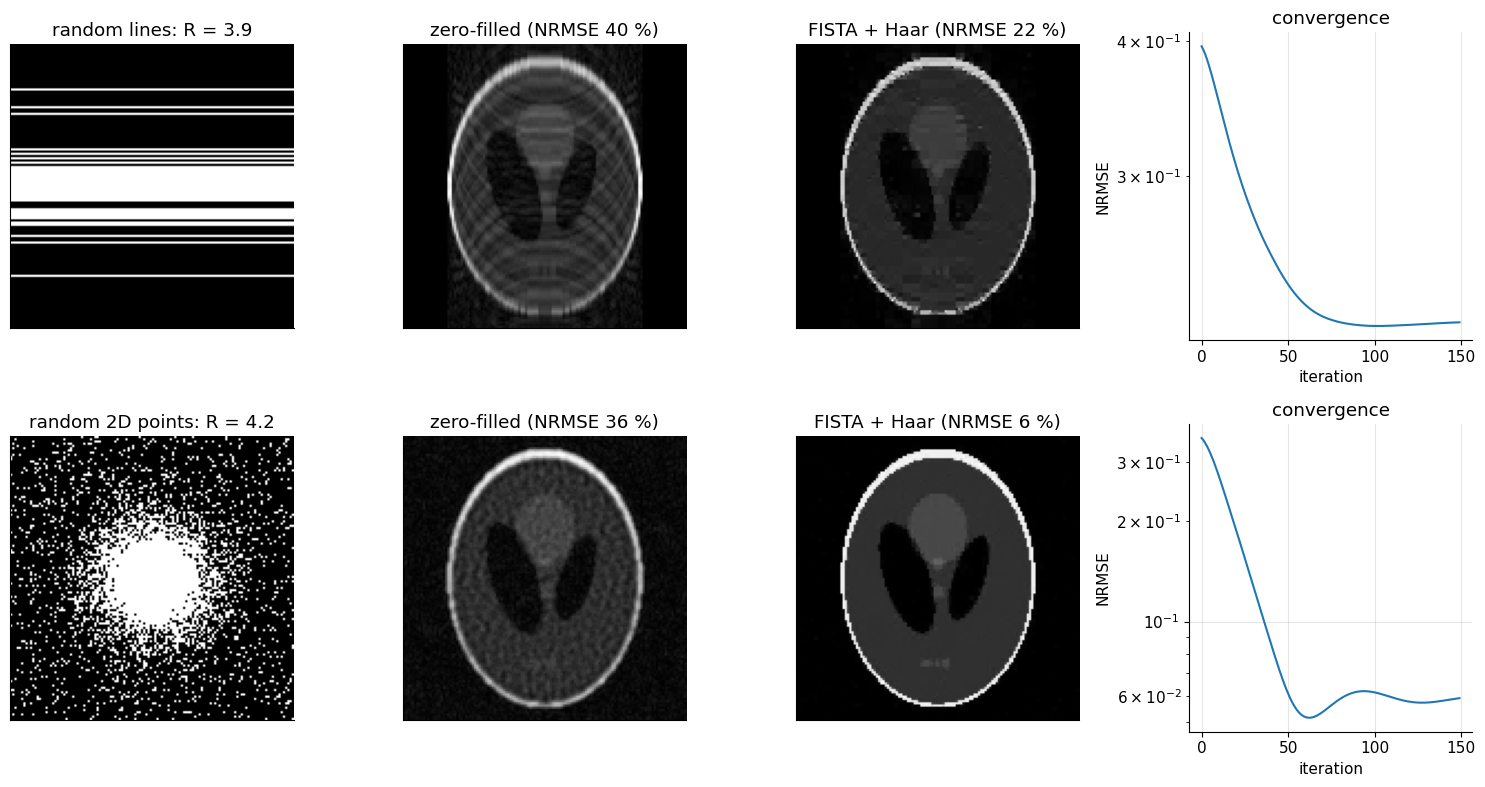

In [17]:
def fista_cs(y, mask, lam, n_iter=150, levels=4, x_true=None):
    """FISTA for min 0.5||mask*F m - y||^2 + lam ||W_detail m||_1 (Haar; coarse band not penalized)."""
    n0 = y.shape[0] >> levels
    x = mt.ifft2c(y); z = x.copy(); tk = 1.0
    errs = []
    for _ in range(n_iter):
        g = z + mt.ifft2c(mask * (y - mask * mt.fft2c(z)))        # gradient step (t = 1)
        c = haar2(g, levels)
        coarse = c[:n0, :n0].copy()
        c = soft_threshold(c, lam)
        c[:n0, :n0] = coarse                                       # keep the low-pass approximation
        x_new = ihaar2(c, levels)
        t_new = (1 + np.sqrt(1 + 4 * tk ** 2)) / 2
        z = x_new + (tk - 1) / t_new * (x_new - x)                 # momentum (FISTA)
        x, tk = x_new, t_new
        if x_true is not None:
            errs.append(np.linalg.norm(np.abs(x) - x_true) / np.linalg.norm(x_true))
    return x, errs

Ni = 128
kc = np.arange(Ni) - Ni // 2
rng = np.random.default_rng(3)
# (a) variable-density random lines
p_line = 0.9 * np.exp(-(kc / 20) ** 2) + 0.1
p_line = np.minimum(p_line * (Ni / 4) / p_line.sum(), 1)
lines = rng.random(Ni) < p_line; lines[np.abs(kc) < 5] = True
mask_lines = np.repeat(lines[:, None], Ni, axis=1)
# (b) variable-density random 2D points
KX, KY = np.meshgrid(kc, kc); kr = np.hypot(KX, KY)
p_pts = 0.9 * np.exp(-(kr / 25) ** 2) + 0.05
p_pts = np.minimum(p_pts * (Ni * Ni / 4) / p_pts.sum(), 1)
mask_pts = rng.random((Ni, Ni)) < p_pts; mask_pts[kr < 5] = True

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for row, (name, mk) in enumerate([("random lines", mask_lines), ("random 2D points", mask_pts)]):
    y = mt.add_complex_noise(mt.fft2c(img), 0.002, rng=np.random.default_rng(4)) * mk
    zf = mt.ifft2c(y)
    rec, errs = fista_cs(y, mk, lam=0.004, x_true=img)
    e_zf = np.linalg.norm(np.abs(zf) - img) / np.linalg.norm(img)
    axes[row, 0].imshow(mk, cmap="gray"); axes[row, 0].set_title(f"{name}: R = {mk.size/mk.sum():.1f}")
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    mt.show_image(zf, ax=axes[row, 1], title=f"zero-filled (NRMSE {e_zf*100:.0f} %)")
    mt.show_image(rec, ax=axes[row, 2], title=f"FISTA + Haar (NRMSE {errs[-1]*100:.0f} %)")
    axes[row, 3].semilogy(errs); axes[row, 3].set_xlabel("iteration"); axes[row, 3].set_ylabel("NRMSE")
    axes[row, 3].set_title("convergence")
plt.tight_layout(); plt.show()

With 2D random sampling (incoherent in both directions) CS removes almost all artifacts at $R\approx4$. With random *lines* only, the aliasing is incoherent in one direction only and CS helps less: some residual streaks remain. This is why CS is most powerful in **3D** and **dynamic** (k–t) imaging, where there are more dimensions to randomize, and why it is usually **combined with parallel imaging** in 2D (see [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) for an $\ell_1$-SENSE example).

Popular sparsifying transforms are **total variation** (TV, the $\ell_1$ norm of the image gradient), total generalized variation (TGV), and **wavelets**, in which MR images are typically sparse. The pseudo-random undersampling typically uses a **variable density** with more samples near the centre of k-space, where most of the energy is.

### 5.5 The regularization parameter λ, SNR, and artifacts

It is difficult to define SNR for compressed sensing reconstructions, since they inherently perform some **denoising** when constraining the reconstruction based on sparsity. The apparent SNR can also vary significantly with the choice of the regularization factor $\lambda$.

The most common artifacts come from **overfitting to the sparsity penalty**: an over-smoothed, unnatural, "cartoon-like" appearance or, with a wavelet transform, **blocking** artifacts. Small, low-contrast features can disappear entirely, since they are "not sparse enough".

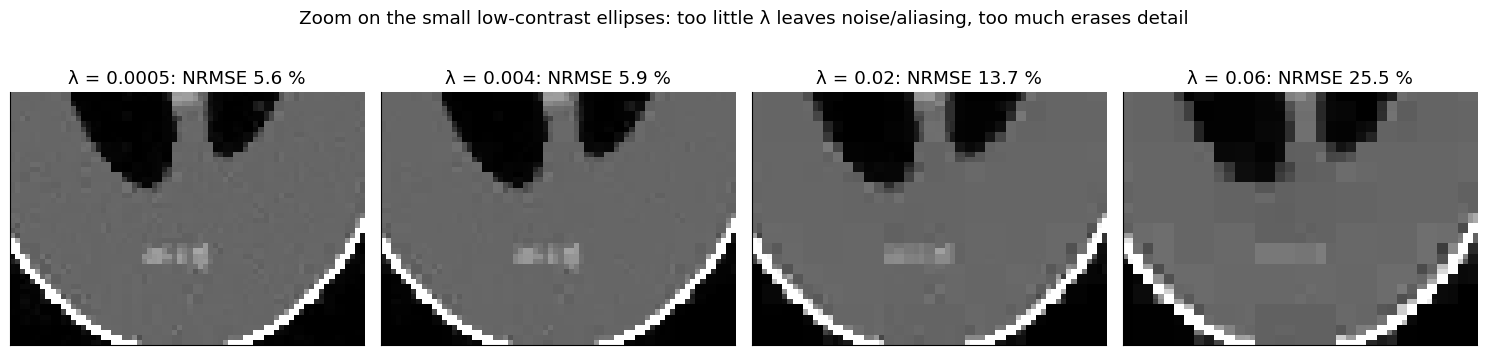

In [18]:
y = mt.add_complex_noise(mt.fft2c(img), 0.002, rng=np.random.default_rng(4)) * mask_pts
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, lam in zip(axes, [0.0005, 0.004, 0.02, 0.06]):
    rec, errs = fista_cs(y, mask_pts, lam=lam, x_true=img)
    mt.show_image(np.abs(rec)[70:120, 30:100], ax=ax, vmin=0, vmax=0.5, title=f"λ = {lam}: NRMSE {errs[-1]*100:.1f} %")
plt.suptitle("Zoom on the small low-contrast ellipses: too little λ leaves noise/aliasing, too much erases detail")
plt.tight_layout(); plt.show()

Small λ: noisy, residual incoherent aliasing. Large λ: clean but blocky, with the three small ellipses at the bottom merged or erased. A radiologist cannot tell from the image alone what was removed, which is why vendors limit CS acceleration factors and tune λ per protocol.

> **🔧 Engineering reality:** CS reconstructions are iterative: tens to hundreds of FFTs per image instead of one. Vendors (Siemens "Compressed Sensing", GE "HyperSense", Philips "Compressed SENSE") run them on GPU-equipped reconstruction computers so that images still appear within seconds to a minute. Clinical CS uses moderate factors (typically 2–8, combined with PI) to limit the risk of artifacts.

## 6. Deep-learning reconstructions

Deep-learning (DL) methods can also reconstruct undersampled k-space into images from a subset of the data. Conceptually they can learn how to incorporate coil sensitivity information, like parallel imaging, and typical image sparsity patterns, like compressed sensing. Because they learn from real-world data, they can learn the information most relevant to MRI data and have been shown to support higher acceleration factors. For example, they can learn which patterns in the image and/or k-space domain are most relevant and most common in MRI.

These methods require learning from large amounts (e.g. thousands or more) of training data, including fully sampled MRI data as the ground truth. Efforts such as the [fastMRI project](http://fastmri.med.nyu.edu) have provided large, high-quality datasets for training and evaluating these methods.

### 6.1 Unrolled networks: ISTA turned into a neural network

So-called **unrolled networks** have become popular for MRI reconstruction because they incorporate parallel imaging information and **data consistency**, and learn common patterns in the data. They mimic a fixed number of iterations of a classical optimization algorithm, each iteration "unrolled" into a stage of a cascaded neural network. Look at one FISTA iteration above:

1. **data-consistency step**: $z + t\,\mathbf E^H(\vec y - \mathbf E z)$, which uses the physics (FFT, sampling mask, coil maps);
2. **regularization step**: $\mathbf W^H\mathcal S_\tau(\mathbf W\,\cdot)$, a hand-designed **denoiser**.

An unrolled network keeps step 1 exactly (physics, no learned weights) and replaces step 2 by a small **convolutional neural network** (CNN, e.g. a U-Net) with learned weights, possibly different for each of the $K$ stages (typically $K$ = 8–12). The whole chain is trained end-to-end by back-propagation to map undersampled data to images that match fully sampled references. Popular examples are **MoDL** and **variational networks** (VarNet).

![Variational network for MRI reconstruction](../images/end-to-end_varnet.jpg)

Caption (from https://arxiv.org/abs/2004.06688): The E2E-VN model takes under-sampled k-space as input and applies several cascades, followed by IFT and RSS. Bottom: the DC (data consistency) module brings intermediate k-space closer to measured values, the Refinement module maps multi-coil k-space to one image, applies a U-Net and maps back to k-space, and the SME estimates sensitivity maps used in the refinement step. (IFT = inverse Fourier transform, RSS = root-sum-of-squares coil combination, SME = sensitivity map estimation.)

A miniature version of "learning" an unrolled network: we unroll $K=8$ FISTA stages and learn one parameter per stage, the threshold $\tau_k$, parameterized as $\tau_k=\tau_0\,q^k$, by grid search on a **training** image. Then we apply the "trained network" to a different **test** image. A real network learns millions of CNN weights instead of 2 numbers, but the logic (fixed physics steps, learned regularization steps, train on one set, test on another) is the same.

In [19]:
def unrolled_fista(y, mask, taus, levels=4):
    """K = len(taus) unrolled FISTA stages, each with its own (learned) threshold."""
    n0 = y.shape[0] >> levels
    x = mt.ifft2c(y); z = x.copy(); tk = 1.0
    for tau in taus:
        g = z + mt.ifft2c(mask * (y - mask * mt.fft2c(z)))        # physics: data consistency
        c = haar2(g, levels); coarse = c[:n0, :n0].copy()
        c = soft_threshold(c, tau); c[:n0, :n0] = coarse            # "denoiser" (would be a CNN)
        x_new = ihaar2(c, levels)
        t_new = (1 + np.sqrt(1 + 4 * tk ** 2)) / 2
        z = x_new + (tk - 1) / t_new * (x_new - x); x, tk = x_new, t_new
    return x

K_stages = 8
train = np.abs(mt.ifft2c(mt.disk_phantom_kspace(128, centers=((-0.2, -0.2), (0.2, 0.1), (0.0, 0.3), (-0.25, 0.25)),
                                                 radius=0.1, values=(1.0, 0.5, 0.8, 0.3))))
test = img
nrmse = lambda a, b: np.linalg.norm(np.abs(a) - b) / np.linalg.norm(b)
meas = lambda im: mt.add_complex_noise(mt.fft2c(im), 0.002, rng=np.random.default_rng(9)) * mask_pts

best = (np.inf, None)
for tau0 in [0.005, 0.01, 0.02, 0.04, 0.08]:
    for q in [0.5, 0.65, 0.8, 1.0]:
        e = nrmse(unrolled_fista(meas(train), mask_pts, tau0 * q ** np.arange(K_stages)), train)
        if e < best[0]:
            best = (e, (tau0, q))
tau0, q = best[1]
print(f"learned on training image: tau0 = {tau0}, q = {q}  (train NRMSE {best[0]*100:.1f} %)")
e_learned = nrmse(unrolled_fista(meas(test), mask_pts, tau0 * q ** np.arange(K_stages)), test)
e_const = nrmse(unrolled_fista(meas(test), mask_pts, [0.004] * K_stages), test)
e_long = nrmse(fista_cs(meas(test), mask_pts, 0.004, n_iter=150)[0], test)
print(f"test image: 8 stages, learned schedule {e_learned*100:.1f} % | 8 stages, constant tau {e_const*100:.1f} % | "
      f"150 FISTA iterations {e_long*100:.1f} %")

learned on training image: tau0 = 0.02, q = 0.8  (train NRMSE 5.8 %)


test image: 8 stages, learned schedule 24.5 % | 8 stages, constant tau 30.0 % | 150 FISTA iterations 5.8 %


Even this 2-parameter "network" with only 8 stages beats 8 iterations with a constant threshold, although it is still far from the 150-iteration result. The idea is that **learning the regularization lets a short, fixed-depth unrolled network do the work of a long iterative reconstruction**. Real DL reconstructions push this much further by learning the denoiser itself.

> **TODO (polish):** improve the toy (more learned parameters / better training image) so the 8-stage result gets closer to the long FISTA result.

### 6.2 SNR, artifacts and honest pros/cons

It is difficult to define SNR for machine-learning reconstructions, since they inherently perform some denoising when constraining the reconstruction.

A challenge with machine-learning reconstructions is that **artifacts can be difficult to identify**. They can produce an over-smoothed appearance, but a well-trained network often retains realistic texture and noise, so the image *looks* right even when it is wrong. These methods can **overfit** to the learned anatomy and data: features might be **erased or hallucinated**. Physics-based (unrolled, data-consistent) techniques give some assurance of consistency with the measured data, but cannot guarantee correctness in the unmeasured part of k-space.

| | Pros | Cons / risks |
|---|---|---|
| Image quality | higher acceleration ($R$ 4–8+) at comparable perceived quality; strong denoising | **hallucination** of plausible but false structures and **erasure** of small/atypical lesions, documented e.g. in the fastMRI challenges; textures can look "too clean" |
| Speed | a forward pass takes well under a second on a GPU | training needs large datasets, GPUs, days of compute |
| Robustness | works across sequences if trained broadly | **distribution shift**: other anatomy, field strength, coil, pathology or sampling than in training can fail unpredictably; small input perturbations can cause large changes (instabilities) |
| Validation | standard metrics (SSIM, PSNR, NRMSE) | metrics correlate imperfectly with diagnostic value; needs reader studies, regulatory clearance; harder to explain or bound errors than linear PI |

> **⚠️ Common confusion:** A sharper, less noisy DL image is not automatically more *correct*. Data consistency only constrains the measured k-space samples; everything else comes from the learned prior. That is why clinical DL products are usually conservative (moderate $R$, mostly used for denoising and modest acceleration) and why rare pathology deserves extra scrutiny.

## Try it yourself (interactive)

Change the SENSE acceleration and the coil count and look at the g-factor. (A static version is in section 4.4.)

In [20]:
try:
    from ipywidgets import interact, IntSlider, Dropdown
    def explore_g(R=2, n_coils=8):
        Cx = coil_sensitivities(N, FOV, n_coils=n_coils)
        _, gx = sense_unfold(np.zeros_like(Cx), Cx, R)
        plt.figure(figsize=(4, 4)); plt.imshow(np.where(obj, gx, np.nan), cmap="inferno", vmin=1, vmax=5)
        plt.colorbar(); plt.title(f"R = {R}, {n_coils} coils: mean g {gx[obj].mean():.2f}"); plt.axis("off"); plt.show()
    interact(explore_g, R=Dropdown(options=[1, 2, 4, 8], value=2), n_coils=IntSlider(min=2, max=16, value=8))
except ImportError:
    print("ipywidgets not available")

interactive(children=(Dropdown(description='R', index=1, options=(1, 2, 4, 8), value=2), IntSlider(value=8, de…

## Key takeaways

* Acceleration = undersampling k-space ($R$× fewer samples) plus a reconstruction that adds prior knowledge; violated assumptions show up as artifacts.
* **Partial Fourier** exploits conjugate symmetry $M(\vec k)=M^*(-\vec k)$ of real images. Real images have smooth phase, so slightly more than half of k-space is acquired and homodyne/POCS correct the low-resolution phase. Avoid it when phase matters.
* **Parallel imaging** uses coil sensitivities $C_n$. SENSE solves a small $N_c\times R$ least-squares system per aliased pixel set, $\hat{\vec v} = (\mathbf C^H\Psi^{-1}\mathbf C)^{-1}\mathbf C^H\Psi^{-1}\vec a$; GRAPPA interpolates missing k-space lines with a kernel calibrated on ACS lines.
* The SNR cost is $SNR_{acc}=SNR_{full}/(g\sqrt R)$; $g=\sqrt{[(\mathbf C^H\Psi^{-1}\mathbf C)^{-1}]_{\rho\rho}[\mathbf C^H\Psi^{-1}\mathbf C]_{\rho\rho}}\ge1$ grows with $R$ and where coils look alike (body centre).
* **SMS/multiband** excites several slices at once (no $\sqrt R$ penalty); CAIPI shifts make the slices separable in-plane and reduce $g$.
* **Compressed sensing** needs sparsity, incoherent (random) sampling and non-linear $\ell_1$ reconstruction (ISTA/FISTA with soft-thresholding). λ trades residual artifacts against over-smoothing; it is most effective in 3D/dynamic imaging and combined with PI.
* **Deep learning** reconstructions (unrolled networks) keep physics-based data consistency and learn the regularizer; they reach high $R$ but can hallucinate or erase features, and need careful validation.

## Check your understanding

1. Why does partial Fourier need slightly more than half of k-space, and what does homodyne do with the extra lines?

<details><summary>Answer</summary>

Conjugate symmetry holds only for real images; real MR images have a (mostly smooth) spatially varying phase from coils, $\Delta B_0$, etc. The extra lines form a symmetric band around $k=0$ from which a low-resolution phase map is estimated. Homodyne removes this phase ($e^{-i\hat\phi}$), weights the one-sided part of k-space by 2 to compensate for the missing half, and takes the real part.

</details>

2. An 8-channel coil and SENSE with $R=4$ give $g=1.8$ in the centre of the brain. If the unaccelerated SNR there is 40, what is the accelerated SNR? What would it be at $R=2$ with $g=1.05$?

<details><summary>Answer</summary>

$R=4$: $40/(1.8\times2)=11.1$. $R=2$: $40/(1.05\times\sqrt2)=26.9$. The $\sqrt R$ part is due to the shorter acquisition; $g$ is the extra noise amplification from unfolding.

</details>

3. In SENSE, what are the dimensions of $\mathbf C$ for $N_c=16$, $R=3$, how many such systems are solved for a 240 × 240 image, and when does the system become impossible?

<details><summary>Answer</summary>

$\mathbf C$ is 16 × 3 (coils × folded pixels). Each system unfolds 3 pixels, so $240\cdot240/3 = 19\,200$ systems. It is impossible (underdetermined) for $R>N_c$, and practically useless (huge $g$) when the columns of $\mathbf C$ are nearly linearly dependent, i.e. when the coils don't vary along the undersampled direction.

</details>

4. Why does compressed sensing use random undersampling, while parallel imaging prefers regular undersampling?

<details><summary>Answer</summary>

CS relies on the aliasing being incoherent (noise-like) in the sparse domain, so that thresholding can separate true coefficients from interference; regular undersampling creates coherent replicas that are as "sparse" as the true signal. SENSE-type PI with regular undersampling gives a small, well-defined number of overlapping pixels per location ($R$), which the coils can separate best (lowest $g$); random patterns also work with iterative PI, but the closed-form pixel-wise SENSE then no longer applies.

</details>

5. What does CAIPIRINHA do in an SMS acquisition and why does it lower the g-factor?

<details><summary>Answer</summary>

It modulates the RF phase of one slice from line to line (e.g. 0°/180°), which by the shift theorem shifts that slice by FOV/2 in the PE direction in the collapsed image. Pixels that overlap then come from different in-plane positions, where the coil sensitivities differ much more than between two slices at the same in-plane position. The unfolding matrix is better conditioned, so $g$ is lower.

</details>

6. Name two failure modes of deep-learning reconstruction that do not occur with SENSE, and one safeguard.

<details><summary>Answer</summary>

Hallucination of plausible structures that are not in the object, and erasure of small or atypical lesions; also unpredictable failure under distribution shift (different scanner, anatomy, pathology) and instability to small perturbations. Safeguards: unrolled architectures with explicit data consistency, conservative acceleration factors, testing on out-of-distribution data, reader studies, and comparing against a conventionally reconstructed (e.g. PI) image when in doubt.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Accelerated Imaging Methods".
Changes: added symbol table; derivation and numerical check of conjugate symmetry; zero-fill / conjugate-fill / homodyne / POCS on real brain data and a failure case; Biot–Savart coil sensitivities; SENSE as a per-pixel linear system with noise covariance, g-factor formula, Monte-Carlo verification of $SNR/(g\sqrt R)$, calibration/mismatch demo; a working GRAPPA implementation; SMS with/without CAIPI; CS from scratch (incoherence, soft-thresholding derivation, ISTA/FISTA with a Haar wavelet, λ trade-off); an unrolled-network "training" toy; a pros/cons table for DL. Corrected the partial-Fourier sampling boundary in the original code, unified the sampling-pattern plots; typos ("k-sapce", "appyling", "illustratid", "regions will little").*